# Qalaisyn — an engine that lets AI understand Kazakh the way people really type it

**Track:** AI + Languages · **Veritas AI International High School Hackathon 2026**

Most phones in Kazakhstan have a **Russian keyboard**, which has no keys for the Kazakh letters
ә ғ қ ң ө ұ ү һ і. People type the closest Russian letter — *калайсын* instead of *қалайсың* — and the AI systems
that now answer bank, airline, clinic and government chats misread them. **Qalaisyn** is a small engine that runs
*inside* those systems and puts the letters back before the AI reads the message.

## Start here — the project in two minutes

**1 · Why one missing letter matters.** On a Russian keyboard *өт* ("go through") is typed as *от* ("fire").
A passenger asks an airline bot *ушак кешигип жатыр ма* — "is the plane late?" — and the translator reads
"is there a rumour going on?". It is like Spanish without accents, where *papá* (dad) and *papa* (potato) merge,
except that it happens in almost every second Kazakh word.

**2 · What Qalaisyn is.** Not a website and not an app. It is a layer inside a company's system, between the
incoming message and the AI that answers — like a spell-checker inside a keyboard. Customers never see it.

1. The customer types on a phone as usual: *ушак кешигип жатыр ма*
2. Inside the company's system, **Qalaisyn** puts the letters back in a few milliseconds: *ұшақ кешігіп жатыр ма*
3. The company's own AI (chatbot, translator, search) now understands and answers: "Flight KC 852 is delayed by 40 minutes."

(The diagram and a live support-bot comparison are shown right below the setup cell and in section 10.)

**3 · Results at a glance** (held-out test data; full details below):

| | Message as typed | Dictionary lookup | **Qalaisyn** |
|---|---|---|---|
| Russian keyboard: words wrong | 47% | 5.8% | **3.5%** |
| Russian keyboard: messages with **every** word right | — | 80% | **88%** |
| Russian keyboard + typos: messages fully right | — | 49% | **74%** |
| Meaning recovered for a translator, Russian keyboard + typos | 0% | 66% | **87%** |
| Meaning recovered, Latin with unseen spellings | 0% | 52% | **87%** |
| Words shown as suggestions · share of its mistakes among them | — | cannot tell | **6% · 63%** |
| Same code on Kyrgyz (Russian keyboard), meaning recovered | — | — | **86%** |

**4 · Why a model and not just a dictionary?** On clean, carefully typed text a dictionary of the most common
spelling is already good, so we tested where it matters:
(a) **whole messages** — a chatbot needs every word right: Qalaisyn gets
88% of messages fully right vs 80%
(+9 percentage points, 95% confidence interval
+7 to +11);
(b) **context** — it fixes 154 of the dictionary's word mistakes while making
38 new ones;
(c) **messy messages** — with typos the gap grows (table above);
(d) **knowing when it is unsure** — a dictionary always guesses silently; Qalaisyn flags its doubtful words.

**5 · Try it.** **Live demo, running in your browser: https://zembono.github.io/qalaisyn/web/** (type any message). Code: https://github.com/ZemBono/qalaisyn.
This notebook can also be run in Colab; all results are already saved below.

*Prototype — not for medical, financial or emergency use.*

**The details:** 1 · Problem and user → 2 · Data → 3 · Simulating how people type → 4 · Models → 5 · Restoration
results → 6 · Does the meaning survive? → 7 · Messy messages → 7b · Kyrgyz → 7c · Suggestions → 7d · Why not a
dictionary? → 8 · Where it fails → 9 · Native-speaker check → 10 · Try it yourself → 11 · Limitations and sources.
Code cells are folded ("Show code"); all source code is in the folded *Setup · Source code* section.

In [1]:
#@title Setup (run first in Colab: downloads the project code and the trained model)
import os, sys, json, subprocess
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/ZemBono/qalaisyn"
if IN_COLAB and not Path("qalaisyn").exists():
    subprocess.run(f"git clone --depth 1 {REPO_URL} qalaisyn", shell=True, check=True)
    subprocess.run("pip -q install sacrebleu transformers==4.46.3 sentencepiece", shell=True)
if IN_COLAB:
    os.chdir("qalaisyn")
ROOT = Path(".").resolve()
(ROOT / "src").mkdir(exist_ok=True)
sys.path.insert(0, str(ROOT / "src"))
print("Running on Colab:", IN_COLAB)

Running on Colab: False


## Setup · Source code (collapsed — click to expand)

All code of the project. Each cell writes one file into `src/`; the sections below import it. Files: `src/chatify.py`, `src/build_data.py`, `src/build_cyr.py`, `src/restore.py`, `src/eval_restore.py`, `src/eval_translate.py`, `src/stress.py`, `src/kyrgyz.py`, `src/confidence.py`, `src/value.py`, `src/analysis.py`, `src/real_eval.py`, `src/latin.py`, `src/app.py`.

In [2]:
%%writefile src/chatify.py
"""chatify: turn standard Cyrillic Kazakh into realistic chat-style Latin Kazakh.

Each simulated writer has a *profile* of typing habits (how they write қ, ә, ш ...).
This is how we create training/test pairs without collecting anyone's private messages.
"""
import random
import re

# For every Cyrillic letter: list of (latin_spelling, weight) per profile.
# Profiles:
#   careful   - uses q, ä, ö, ü, ğ, ñ (close to the official Latin alphabet)
#   typical   - q for қ, but drops other special letters (most common in chats)
#   minimal   - only plain ASCII, no q (k for both к and қ)
#   mixed     - typical + random variation between habits inside one message
BASE = {
    "а": "a", "б": "b", "в": "v", "г": "g", "д": "d", "е": "e", "ё": "yo",
    "ж": "zh", "з": "z", "и": "i", "й": "i", "к": "k", "л": "l", "м": "m",
    "н": "n", "о": "o", "п": "p", "р": "r", "с": "s", "т": "t", "у": "u",
    "ф": "f", "х": "h", "ц": "ts", "ч": "ch", "ш": "sh", "щ": "sh", "ъ": "",
    "ы": "y", "ь": "", "э": "e", "ю": "yu", "я": "ya",
    "ә": "a", "ғ": "g", "қ": "k", "ң": "n", "ө": "o", "ұ": "u", "ү": "u",
    "һ": "h", "і": "i",
}

# Options per letter for each profile: list of (spelling, probability).
PROFILES = {
    "careful": {
        "қ": [("q", 1.0)], "ә": [("ä", 0.8), ("a", 0.2)], "ө": [("ö", 0.8), ("o", 0.2)],
        "ү": [("ü", 0.8), ("u", 0.2)], "ұ": [("u", 1.0)], "ғ": [("ğ", 0.5), ("g", 0.5)],
        "ң": [("ñ", 0.4), ("ng", 0.3), ("n", 0.3)], "і": [("i", 1.0)], "ы": [("y", 0.8), ("ı", 0.2)],
        "ш": [("sh", 0.7), ("ş", 0.3)], "ж": [("zh", 0.5), ("j", 0.5)], "х": [("h", 0.5), ("x", 0.5)],
        "й": [("i", 0.5), ("y", 0.5)], "у": [("u", 0.8), ("w", 0.2)], "ч": [("ch", 1.0)],
    },
    "typical": {
        "қ": [("q", 0.85), ("k", 0.15)], "ә": [("a", 0.9), ("ä", 0.1)], "ө": [("o", 1.0)],
        "ү": [("u", 1.0)], "ұ": [("u", 1.0)], "ғ": [("g", 0.85), ("gh", 0.15)],
        "ң": [("n", 0.7), ("ng", 0.3)], "і": [("i", 1.0)], "ы": [("y", 0.7), ("i", 0.3)],
        "ш": [("sh", 0.75), ("w", 0.25)], "ж": [("zh", 0.4), ("j", 0.6)], "х": [("h", 0.5), ("x", 0.5)],
        "й": [("i", 0.6), ("y", 0.4)], "у": [("u", 0.85), ("w", 0.15)], "ч": [("ch", 1.0)],
    },
    "minimal": {
        "қ": [("k", 1.0)], "ә": [("a", 1.0)], "ө": [("o", 1.0)], "ү": [("u", 1.0)],
        "ұ": [("u", 1.0)], "ғ": [("g", 1.0)], "ң": [("n", 1.0)], "і": [("i", 1.0)],
        "ы": [("i", 0.6), ("y", 0.4)], "ш": [("sh", 0.6), ("w", 0.4)], "ж": [("j", 0.7), ("zh", 0.3)],
        "х": [("h", 0.6), ("x", 0.4)], "й": [("i", 0.7), ("y", 0.3)], "у": [("u", 1.0)], "ч": [("ch", 1.0)],
    },
}
PROFILE_NAMES = ["careful", "typical", "minimal", "mixed"]

_word_re = re.compile(r"[а-яёәғқңөұүһі]+(?:-[а-яёәғқңөұүһі]+)*|\d+", re.IGNORECASE)


def normalize_cyr(text: str) -> str:
    """Gold format: lowercase Cyrillic words and numbers, no punctuation."""
    text = text.lower().replace("ё", "е")
    # common look-alike Latin letters inside Cyrillic text
    text = text.translate(str.maketrans({"i": "і", "a": "а", "o": "о", "e": "е", "c": "с", "p": "р"}))
    return " ".join(_word_re.findall(text))


def _pick(options, rng):
    r = rng.random()
    acc = 0.0
    for spelling, p in options:
        acc += p
        if r <= acc:
            return spelling
    return options[-1][0]


def chatify(text: str, profile: str = "typical", rng: random.Random | None = None) -> str:
    """Convert (already normalized) Cyrillic Kazakh into chat-style Latin."""
    rng = rng or random.Random(0)
    text = normalize_cyr(text)
    out = []
    # a writer keeps the same habit for a letter inside one message (more realistic)
    habits = {}
    for ch in text:
        prof = profile
        if profile == "mixed":
            prof = rng.choice(["careful", "typical", "minimal"])
            habit_key = ch + prof
        else:
            habit_key = ch
        table = PROFILES[prof]
        if ch in table:
            if habit_key not in habits or profile == "mixed":
                habits[habit_key] = _pick(table[ch], rng)
            out.append(habits[habit_key])
        elif ch in BASE:
            out.append(BASE[ch])
        else:
            out.append(ch)
    s = "".join(out)
    # chat noise: occasionally drop a hyphen, double a final letter for emphasis
    if rng.random() < 0.3:
        s = s.replace("-", " ")
    return re.sub(r"\s+", " ", s).strip()


# ---------------------------------------------------------------- Cyrillic chat styles
# The most common case in Kazakhstan: Cyrillic typed on a *Russian* keyboard, so the
# Kazakh-only letters are replaced by the closest Russian ones.
RU_KEYBOARD = {
    "ә": [("а", 1.0)], "ғ": [("г", 1.0)], "қ": [("к", 1.0)], "ң": [("н", 1.0)],
    "ө": [("о", 1.0)], "ұ": [("у", 1.0)], "ү": [("у", 1.0)], "һ": [("х", 1.0)],
    "і": [("и", 0.75), ("ы", 0.1), ("i", 0.15)],   # some type Latin i for і
}
CYR_PROFILES = ["ru-keyboard", "partial"]


def chatify_cyr(text: str, profile: str = "ru-keyboard", rng: random.Random | None = None) -> str:
    """Cyrillic chat style. ru-keyboard: every Kazakh letter replaced.
    partial: the writer has a Kazakh keyboard but keeps only some letters (per-letter habit)."""
    rng = rng or random.Random(0)
    text = normalize_cyr(text)
    keep = {ch: (profile == "partial" and rng.random() < 0.5) for ch in RU_KEYBOARD}
    habits, out = {}, []
    for ch in text:
        if ch in RU_KEYBOARD and not keep[ch]:
            if ch not in habits:
                habits[ch] = _pick(RU_KEYBOARD[ch], rng)
            out.append(habits[ch])
        else:
            out.append(ch)
    s = "".join(out)
    if rng.random() < 0.3:
        s = s.replace("-", " ")
    return re.sub(r"\s+", " ", s).strip()


UNSEEN = {"ә": "ae", "ө": "oe", "ү": "ue", "х": "kh", "қ": "kk", "ғ": "gg"}


def add_typos(chat: str, rate: float, rng: random.Random) -> str:
    """Realistic thumb typos: drop, double or swap letters in some words."""
    out = []
    for w in chat.split():
        if len(w) > 3 and not w.isdigit() and rng.random() < rate:
            i = rng.randrange(1, len(w) - 1)
            kind = rng.choice(["drop", "double", "swap"])
            if kind == "drop":
                w = w[:i] + w[i + 1:]
            elif kind == "double":
                w = w[:i] + w[i] + w[i:]
            else:
                w = w[:i] + w[i + 1] + w[i] + w[i + 2:]
        out.append(w)
    return " ".join(out)


def chatify_unseen(text: str, rng: random.Random) -> str:
    """A writer with habits the model was never told about (ae for ә, kh for х, kk for қ ...)."""
    text = normalize_cyr(text)
    s = "".join(UNSEEN.get(ch, PROFILES["minimal"].get(ch, [(BASE.get(ch, ch), 1)])[0][0]) for ch in text)
    return re.sub(r"\s+", " ", s).strip()


if __name__ == "__main__":
    demo = "Баламның қызуы 39 көтерілді, не істеу керек?"
    for p in PROFILE_NAMES:
        print(f"{p:8s} -> {chatify(demo, p, random.Random(1))}")

Overwriting src/chatify.py


In [3]:
%%writefile src/build_data.py
"""Build training corpus and held-out test sets.

Training text : Kazakh Wikipedia + Tatoeba Kazakh sentences (minus test sentences)
Test sets     : FLORES-200 devtest (kaz + professional English), Tatoeba kaz-eng pairs
Tuning set    : FLORES-200 dev
Nothing from a test set is allowed into training.
"""
import bz2
import json
import random
import re
import sys
from pathlib import Path

import pyarrow.parquet as pq

sys.path.insert(0, str(Path(__file__).parent))
from chatify import PROFILE_NAMES, chatify, normalize_cyr  # noqa: E402

ROOT = Path(__file__).resolve().parents[1]
RAW = ROOT / "data" / "raw"
OUT = ROOT / "data" / "processed"
OUT.mkdir(parents=True, exist_ok=True)

CYR = re.compile(r"[а-яёәғқңөұүһі]", re.I)
LAT = re.compile(r"[a-z]", re.I)
SENT_SPLIT = re.compile(r"(?<=[.!?…])\s+|\n+")


def good_sentence(s: str) -> bool:
    n_cyr, n_lat = len(CYR.findall(s)), len(LAT.findall(s))
    words = s.split()
    return 3 <= len(words) <= 40 and n_cyr > 10 * (n_lat + 1) / 2 and n_lat < 3


def read_lines(p):
    return [l.rstrip("\n") for l in open(p, encoding="utf-8")]


def main(max_wiki=1_500_000):
    # ---------------- test sets
    fl = RAW / "flores200_dataset"
    flores_test = list(zip(read_lines(fl / "devtest/kaz_Cyrl.devtest"), read_lines(fl / "devtest/eng_Latn.devtest")))
    flores_dev = list(zip(read_lines(fl / "dev/kaz_Cyrl.dev"), read_lines(fl / "dev/eng_Latn.dev")))

    kaz = {}
    for line in open(RAW / "kaz_sentences.tsv", encoding="utf-8"):
        sid, _, text = line.rstrip("\n").split("\t", 2)
        kaz[sid] = text
    links = [l.split() for l in read_lines(RAW / "kaz-eng_links.tsv")]
    need_eng = {e for _, e in links}
    eng = {}
    with open(RAW / "eng_sentences.tsv", encoding="utf-8") as f:
        for line in f:
            sid, _, text = line.rstrip("\n").split("\t", 2)
            if sid in need_eng:
                eng[sid] = text
    tat_pairs, seen = [], set()
    for k, e in links:
        if k in kaz and e in eng and k not in seen:
            seen.add(k)
            tat_pairs.append((kaz[k], eng[e]))
    tat_test_ids = seen

    test_norm = {normalize_cyr(k) for k, _ in flores_test + flores_dev + tat_pairs}

    # ---------------- training text
    tat_train = [normalize_cyr(t) for sid, t in kaz.items() if sid not in tat_test_ids]
    tat_train = [s for s in tat_train if s and s not in test_norm]

    wiki, wseen = [], set()
    pf = pq.ParquetFile(RAW / "kkwiki.parquet")
    for batch in pf.iter_batches(columns=["text"], batch_size=2000):
        for doc in batch.column(0).to_pylist():
            for s in SENT_SPLIT.split(doc):
                s = s.strip()
                if not good_sentence(s):
                    continue
                n = normalize_cyr(s)
                if len(n.split()) < 3 or n in wseen or n in test_norm:
                    continue
                wseen.add(n)
                wiki.append(n)
        if len(wiki) >= max_wiki:
            break
    random.Random(0).shuffle(wiki)

    (OUT / "train_wiki.txt").write_text("\n".join(wiki), encoding="utf-8")
    (OUT / "train_tatoeba.txt").write_text("\n".join(tat_train), encoding="utf-8")

    # ---------------- chat-style versions of the test sets (4 writer profiles)
    def make(pairs, name):
        rows = []
        for i, (k, e) in enumerate(pairs):
            for p in PROFILE_NAMES:
                rng = random.Random(f"{name}-{i}-{p}")
                rows.append({"id": i, "profile": p, "kaz": k, "gold": normalize_cyr(k),
                             "chat": chatify(k, p, rng), "eng": e})
        with open(OUT / f"{name}.jsonl", "w", encoding="utf-8") as f:
            for r in rows:
                f.write(json.dumps(r, ensure_ascii=False) + "\n")
        return rows

    make(flores_test, "test_flores")
    make(tat_pairs, "test_tatoeba")
    make(flores_dev, "dev_flores")
    print(f"wiki sentences: {len(wiki):,}  tatoeba train: {len(tat_train):,}")
    print(f"test: flores {len(flores_test)}, tatoeba {len(tat_pairs)}; dev flores {len(flores_dev)}")


if __name__ == "__main__":
    main()

Overwriting src/build_data.py


In [4]:
%%writefile src/build_cyr.py
"""Cyrillic chat-style test sets (Russian keyboard / partial Kazakh keyboard) from the same held-out sentences."""
import json
import random
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).parent))
from chatify import CYR_PROFILES, chatify_cyr  # noqa: E402

P = Path(__file__).resolve().parents[1] / "data" / "processed"

for name in ["test_tatoeba", "test_flores", "dev_flores"]:
    seen, rows = set(), []
    for line in open(P / f"{name}.jsonl", encoding="utf-8"):
        r = json.loads(line)
        if r["id"] in seen:
            continue
        seen.add(r["id"])
        for p in CYR_PROFILES:
            rr = {k: r[k] for k in ("id", "kaz", "gold", "eng")}
            rr["profile"] = p
            rr["chat"] = chatify_cyr(r["kaz"], p, random.Random(f"{name}-{r['id']}-{p}"))
            rows.append(rr)
    with open(P / f"{name}_cyr.jsonl", "w", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
    print(name, len(rows), "messages")

Overwriting src/build_cyr.py


In [5]:
%%writefile src/restore.py
"""Restore standard Cyrillic Kazakh from chat-style Latin Kazakh.

Three restorers, from simplest to ours:
  B1  RuleRestorer        - every Latin letter -> its most common Cyrillic letter
  B2  DictRestorer        - every word -> its most frequent matching Kazakh word
  M1  QalaisynRestorer    - candidate words + typing-habit channel model
                            + word n-gram language model (Viterbi over the sentence)
                            + character n-gram model for unknown words
"""
from __future__ import annotations

import math
import re
from collections import Counter, defaultdict
from pathlib import Path

# ---------------------------------------------------------------- canonical keys
# Every Cyrillic letter is reduced to a "skeleton" letter. Words that look the
# same once the special Kazakh letters are stripped share a skeleton.
CANON = {
    "а": "a", "ә": "a", "б": "b", "в": "v", "г": "g", "ғ": "g", "д": "d", "е": "e",
    "э": "e", "ж": "j", "з": "z", "и": "i", "й": "i", "і": "i", "ы": "i", "к": "k",
    "қ": "k", "л": "l", "м": "m", "н": "n", "ң": "n", "о": "o", "ө": "o", "п": "p",
    "р": "r", "с": "s", "т": "t", "у": "u", "ұ": "u", "ү": "u", "ф": "f", "х": "h",
    "һ": "h", "ц": "c", "ч": "C", "ш": "S", "щ": "S", "ъ": "", "ь": "", "ю": "iu",
    "я": "ia", "ё": "io", "-": "-",
}


def canon_word(word: str) -> str:
    return "".join(CANON.get(ch, ch) for ch in word)


# Chat-side parsing: each position may be read in several ways.
_MULTI = [
    ("sh", ["S"]), ("zh", ["j"]), ("ch", ["C"]), ("gh", ["g"]),
    ("ts", ["c", "ts"]), ("ng", ["n", "ng"]),
]
_SINGLE = {
    "q": ["k"], "ä": ["a"], "ö": ["o"], "ü": ["u"], "ı": ["i"], "y": ["i"],
    "ğ": ["g"], "ñ": ["n"], "ş": ["S"], "x": ["h"], "w": ["S", "u", "v"],
    "c": ["c", "C", "s"], "j": ["j"],
}
# Latin markers that can only come from one special Kazakh letter.
STRICT = {"q": "қ", "ä": "ә", "ö": "ө", "ü": "ү", "ğ": "ғ", "ñ": "ң", "ı": "ы", "ş": "ш"}


def clean_token(tok: str) -> str:
    return re.sub(r"['`’]", "", tok.lower())


def chat_variants(tok: str, limit: int = 32) -> list[str]:
    tok = clean_token(tok)
    results = [""]
    i = 0
    while i < len(tok):
        opts = None
        for pat, outs in _MULTI:
            if tok.startswith(pat, i):
                opts, step = outs, len(pat)
                break
        if opts is None:
            ch = tok[i]
            if ch in _SINGLE:
                opts = _SINGLE[ch]
            elif ch in CANON:          # Cyrillic input (e.g. typed on a Russian keyboard)
                opts = [CANON[ch]]
            else:
                opts = [ch]
            step = 1
        results = [r + o for r in results for o in opts][:limit]
        i += step
    return results


# ---------------------------------------------------------------- B1: rules
RULE_MULTI = [("sh", "ш"), ("zh", "ж"), ("ch", "ч"), ("gh", "ғ"), ("ts", "ц"),
              ("yu", "ю"), ("ya", "я"), ("yo", "ё"), ("ng", "ң")]
RULE_SINGLE = {
    "a": "а", "b": "б", "c": "ц", "d": "д", "e": "е", "f": "ф", "g": "г", "h": "х",
    "i": "і", "j": "ж", "k": "к", "l": "л", "m": "м", "n": "н", "o": "о", "p": "п",
    "q": "қ", "r": "р", "s": "с", "t": "т", "u": "у", "v": "в", "w": "у", "x": "х",
    "y": "ы", "z": "з", "ä": "ә", "ö": "ө", "ü": "ү", "ğ": "ғ", "ñ": "ң", "ı": "ы", "ş": "ш",
}


def rule_word(tok: str) -> str:
    tok = clean_token(tok)
    if tok.isdigit():
        return tok
    out, i = [], 0
    while i < len(tok):
        for pat, cyr in RULE_MULTI:
            if tok.startswith(pat, i):
                out.append(cyr)
                i += len(pat)
                break
        else:
            out.append(RULE_SINGLE.get(tok[i], tok[i]))
            i += 1
    return "".join(out)


class RuleRestorer:
    name = "B1 rules"

    def restore(self, text: str) -> str:
        return " ".join(rule_word(t) for t in text.split())


# ---------------------------------------------------------------- shared lexicon
def strict_ok(tok: str, word: str) -> bool:
    """A chat token with 'q' must come from a word with at least that many 'қ', etc."""
    t = clean_token(tok)
    for lat, cyr in STRICT.items():
        if t.count(lat) > word.count(cyr):
            return False
    for cyr in "әғқңөұүһі":                 # a Kazakh letter that was typed must stay
        if t.count(cyr) > word.count(cyr):
            return False
    return True


PARTICLES = {"ма", "ме", "ба", "бе", "па", "пе", "ma", "me", "ba", "be", "pa", "pe"}
# Very short chat contractions that typo search would otherwise turn into an unrelated word (жатм -> атом).
# Longer colloquial forms (жатсың, кешіп келем, боп, кеп, барам) are already in the training text.
CONTRACTIONS = {"жатм": "жатырмын", "жатрм": "жатырмын", "жатырм": "жатырмын",
                "jatm": "жатырмын", "jatyrm": "жатырмын", "zhatyrm": "жатырмын"}


def _load_russian(n=30000):
    p = Path(__file__).resolve().parents[1] / "data" / "ru_words.txt"
    if not p.exists():
        return set()
    return {line.split()[0] for line in p.read_text(encoding="utf-8").splitlines()[:n] if line.strip()}


RUSSIAN_WORDS = _load_russian()

# Which typed characters show that the writer *can* type a given Kazakh letter.
MARKERS = {"қ": "qқ", "ә": "äә", "ө": "öө", "ү": "üү", "ғ": "ğғ", "ң": "ñң", "ұ": "ұ", "і": "і", "һ": "һ"}


class Lexicon:
    def __init__(self):
        self.uni = Counter()
        self.bi = Counter()
        self.ctx = Counter()           # number of tokens following a word
        self.followers = Counter()     # distinct followers (Witten-Bell)
        self.by_key = defaultdict(list)
        self.total = 0
        self.char = None

    def fit(self, sentences, weights=None):
        weights = weights or [1] * len(sentences)
        for sent, w in zip(sentences, weights):
            words = ["<s>"] + sent.split() + ["</s>"]
            for a, b in zip(words, words[1:]):
                self.uni[b] += w
                if self.bi[(a, b)] == 0:
                    self.followers[a] += 1
                self.bi[(a, b)] += w
                self.ctx[a] += w
        self.total = sum(self.uni.values())
        for word, c in self.uni.items():
            if word in ("</s>",) or word.isdigit():
                continue
            self.by_key[canon_word(word)].append((c, word))
        for k in self.by_key:
            self.by_key[k].sort(reverse=True)
        self.char = CharLM(order=5).fit(self.uni)
        return self

    def prune(self, min_bigram=2, min_word=2):
        """Drop word pairs and words seen fewer than `min_*` times. Their probability mass stays in the
        back-off (ctx/followers keep the full counts), so rare pairs fall back to word frequencies.
        This cuts memory several times with little effect on accuracy (see notebook)."""
        self.bi = Counter({k: v for k, v in self.bi.items() if v >= min_bigram})
        keep = {w for w, c in self.uni.items() if c >= min_word or w in ("</s>",)}
        self.by_key = defaultdict(list)
        for word in keep:
            if word == "</s>" or word.isdigit():
                continue
            self.by_key[canon_word(word)].append((self.uni[word], word))
        for k in self.by_key:
            self.by_key[k].sort(reverse=True)
        if self.char is not None:
            self.char.counts = Counter({g: c for g, c in self.char.counts.items() if c >= 2})
        if hasattr(self, "del_index"):
            del self.del_index
        return self

    def p_uni(self, w):
        return (self.uni.get(w, 0) + 0.1) / (self.total + 0.1 * (len(self.uni) + 1))

    def logp(self, w, prev):
        """Interpolated bigram (Witten-Bell)."""
        pu = self.p_uni(w)
        c_prev = self.ctx.get(prev, 0)
        if c_prev == 0:
            return math.log(pu)
        t = self.followers[prev]
        lam = c_prev / (c_prev + t)
        return math.log(lam * self.bi.get((prev, w), 0) / c_prev + (1 - lam) * pu)

    def candidates(self, tok, top=25):
        seen = {}
        for key in chat_variants(tok):
            for c, w in self.by_key.get(key, [])[:top]:
                if strict_ok(tok, w):
                    seen[w] = max(seen.get(w, 0), c)
        return sorted(seen, key=seen.get, reverse=True)[:top]

    # ---- typo tolerance: words one edit away (symmetric-delete index)
    def build_fuzzy(self, min_count=3):
        self.del_index = defaultdict(set)
        for key, lst in self.by_key.items():
            if lst[0][0] < min_count or len(key) < 4:
                continue
            for i in range(len(key)):
                self.del_index[key[:i] + key[i + 1:]].add(key)
        return self

    def fuzzy_candidates(self, tok, top=10):
        if not hasattr(self, "del_index"):
            return []
        found = {}
        for v in chat_variants(tok, limit=8):
            if len(v) < 4:
                continue
            dels = {v[:i] + v[i + 1:] for i in range(len(v))}
            keys = set(self.del_index.get(v, ()))            # input lost a letter
            for d in dels:
                if d in self.by_key:                          # input has an extra letter
                    keys.add(d)
                keys |= self.del_index.get(d, set())          # swapped / substituted letter
            keys.discard(v)
            for k in keys:
                for c, w in self.by_key[k][:3]:
                    if strict_ok(tok, w):
                        found[w] = max(found.get(w, 0), c)
        return sorted(found, key=found.get, reverse=True)[:top]


# ---------------------------------------------------------------- character LM
# Which Cyrillic letters a skeleton letter can stand for.
CHAR_OPTS = {
    "a": "аә", "k": "кқ", "o": "оө", "u": "уұү", "i": "іиыйю", "n": "нң", "g": "гғ",
    "h": "хһ", "e": "еэ", "S": "шщ", "j": "ж", "C": "ч", "c": "цс", "b": "б", "v": "в",
    "d": "д", "z": "з", "l": "л", "m": "м", "p": "п", "r": "р", "s": "с", "t": "т",
    "f": "ф", "-": "-",
}
STRICT_SKEL = {"q": "қ", "ä": "ә", "ö": "ө", "ü": "ү", "ğ": "ғ", "ñ": "ң", "ı": "ы", "ş": "ш"}
# Cyrillic typed on a Russian keyboard: which Kazakh letters each Russian letter may stand for
CYR_OPTS = {"а": "аә", "г": "гғ", "к": "кқ", "н": "нң", "о": "оө", "у": "уұү", "х": "хһ", "и": "иі", "ы": "ыі"}


class CharLM:
    def __init__(self, order=5):
        self.n = order
        self.counts = Counter()
        self.ctx = Counter()

    def fit(self, word_counts):
        for w, c in word_counts.items():
            if not w or w in ("<s>", "</s>") or w.isdigit():
                continue
            s = "^" * (self.n - 1) + w + "$"
            for i in range(self.n - 1, len(s)):
                for k in range(1, self.n + 1):
                    gram = s[i - k + 1:i + 1]
                    self.counts[gram] += c
                    self.ctx[gram[:-1]] += c
        return self

    def logp(self, history, ch):
        """Stupid backoff, good enough for ranking."""
        alpha = 0.0
        for k in range(self.n - 1, -1, -1):
            h = history[-k:] if k else ""
            c = self.counts.get(h + ch, 0)
            if c:
                return alpha + math.log(c / self.ctx[h])
            alpha += math.log(0.4)
        return alpha + math.log(1e-6)

    def restore(self, tok, beam=16):
        t = clean_token(tok)
        # parse into slots, each slot = list of cyrillic options (may be multi-char)
        slots, i = [], 0
        while i < len(t):
            two = t[i:i + 2]
            if two in ("sh", "zh", "ch", "gh"):
                slots.append({"sh": ["ш"], "zh": ["ж"], "ch": ["ч"], "gh": ["ғ"]}[two])
                i += 2
                continue
            if two in ("yu", "iu"):
                slots.append(["ю", "иу", "ыу", "йу", "іу"])
                i += 2
                continue
            if two in ("ya", "ia"):
                slots.append(["я", "иа", "ыа", "йа"])
                i += 2
                continue
            if two == "ng":
                slots.append(["ң", "нг"])
                i += 2
                continue
            ch = t[i]
            if ch in CYR_OPTS:
                slots.append(list(CYR_OPTS[ch]))
            elif ch in STRICT_SKEL:
                slots.append([STRICT_SKEL[ch]])
            elif ch == "y":
                slots.append(["ы", "й", "и"])
            elif ch == "w":
                slots.append(["ш", "у"])
            elif ch == "x":
                slots.append(["х", "һ"])
            elif ch in CHAR_OPTS:
                slots.append(list(CHAR_OPTS[ch]))
            else:
                slots.append([ch])
            i += 1
        hyps = [("^" * (self.n - 1), 0.0)]
        for opts in slots:
            new = []
            for h, s in hyps:
                for o in opts:
                    sc, hh = s, h
                    for c in o:
                        sc += self.logp(hh, c)
                        hh += c
                    new.append((hh, sc))
            new.sort(key=lambda x: -x[1])
            hyps = new[:beam]
        best = max(hyps, key=lambda x: x[1] + self.logp(x[0], "$"))
        return best[0][self.n - 1:]


# ---------------------------------------------------------------- B2: dictionary
class DictRestorer:
    name = "B2 dictionary"

    def __init__(self, lex: Lexicon):
        self.lex = lex

    def restore(self, text: str) -> str:
        out = []
        for tok in text.split():
            if tok.isdigit():
                out.append(tok)
                continue
            cands = self.lex.candidates(tok, top=1)
            out.append(cands[0] if cands else rule_word(tok))
        return " ".join(out)


# ---------------------------------------------------------------- M1: Qalaisyn
class QalaisynRestorer:
    name = "M1 Qalaisyn"

    def __init__(self, lex: Lexicon, habit_penalty=math.log(0.1), oov_penalty=-12.0,
                 top=25, use_char=True, fuzzy=False, typo_penalty=math.log(0.002),
                 name=None, fuzzy_below=5, char_bonus=0.0):
        # defaults for fuzzy_below / typo_penalty / char_bonus were tuned on FLORES dev only
        self.char_bonus = char_bonus
        self.fuzzy_below = fuzzy_below   # look for typo neighbours only if the word is unknown/rare
        self.lex = lex
        self.habit_penalty = habit_penalty
        self.oov_penalty = oov_penalty
        self.top = top
        self.use_char = use_char
        self.fuzzy = fuzzy
        self.typo_penalty = typo_penalty
        if name:
            self.name = name
        if fuzzy and not hasattr(lex, "del_index"):
            lex.build_fuzzy()

    def _channel(self, tok, word, habits):
        """Typing-habit model: if this writer can type қ (as 'q' or 'қ') somewhere in the message,
        a plain 'k'/'к' elsewhere is probably really к. Same for the other Kazakh letters."""
        if not habits:
            return 0.0
        t = clean_token(tok)
        pen = 0.0
        for s in habits:
            extra = word.count(s) - sum(t.count(m) for m in MARKERS[s])
            if extra > 0:
                pen += self.habit_penalty * extra
        return pen

    # ---- chat language that is not standard Kazakh
    def split_particles(self, toks):
        """Question particles typed together with the word: 'болама' -> 'бола ма', 'барасынба' -> 'барасын ба'.
        Split only if the whole form is rare compared with its stem."""
        out = []
        for tok in toks:
            t = clean_token(tok)
            parts = [tok]
            if len(t) >= 5 and t[-2:] in PARTICLES:
                whole = self.lex.candidates(t, 1)
                whole_count = self.lex.uni.get(whole[0], 0) if whole else 0
                stem = self.lex.candidates(t[:-2], 1)
                stem_count = self.lex.uni.get(stem[0], 0) if stem else 0
                # split when the stem is far more common than the whole form (болама: 3 vs бола: 3234),
                # but not for real words like әжеме ("to my grandma": 4 vs әже: 83)
                if stem_count >= 20 and (whole_count == 0 or stem_count >= 200 * whole_count):
                    parts = [t[:-2], t[-2:]]
            out.extend(parts)
        return out

    def is_russian(self, tok):
        """Russian words inside a Kazakh message (короче, доставка, щас) must be left alone.
        A word counts as Russian if it has letters Kazakh words do not use (щ, ё, ъ, э), or if it is a common
        Russian word and no *different* Kazakh word with the same letters is common."""
        t = clean_token(tok)
        if not re.fullmatch(r"[а-яё-]+", t):        # Cyrillic without Kazakh letters only
            return False
        if re.search(r"[щёъэ]", t):
            return True
        if t not in RUSSIAN_WORDS:
            return False
        others = [w for w in self.lex.candidates(t, 5) if w != t]
        return not others or self.lex.uni.get(others[0], 0) < 50

    def restore(self, text: str, explain: bool = False):
        toks = self.split_particles(text.split())
        if not toks:
            return ""
        low = text.lower()
        uses_q = {s for s, marks in MARKERS.items() if any(m in low for m in marks)}
        lattice = []
        for tok in toks:
            if tok.isdigit():
                lattice.append([(tok, 0.0)])
                continue
            if self.is_russian(tok):
                lattice.append([(clean_token(tok), 0.0)])
                continue
            if clean_token(tok) in CONTRACTIONS:
                lattice.append([(CONTRACTIONS[clean_token(tok)], 0.0)])
                continue
            cands = self.lex.candidates(tok, self.top)
            opts = [(w, self._channel(tok, w, uses_q)) for w in cands]
            best_count = self.lex.uni.get(cands[0], 0) if cands else 0
            if self.fuzzy and len(tok) >= 4 and best_count < self.fuzzy_below:
                have = set(cands)
                fz = [w for w in self.lex.fuzzy_candidates(tok) if w not in have]
                for w in fz:
                    opts.append((w, self.typo_penalty + self._channel(tok, w, uses_q)))
                if fz and not cands:
                    # keep the letter-by-letter guess in the race (rare names, new words)
                    opts.append((self.lex.char.restore(tok), self.char_bonus))
            if not opts:
                guess = self.lex.char.restore(tok) if self.use_char else rule_word(tok)
                opts = [(guess, self.oov_penalty)]
            lattice.append(opts)
        # Viterbi over candidate words with the bigram LM
        best = {"<s>": (0.0, [])}
        for opts in lattice:
            new = {}
            for w, ch_score in opts:
                cand_best = None
                for prev, (s, path) in best.items():
                    sc = s + ch_score + self.lex.logp(w, prev)
                    if cand_best is None or sc > cand_best[0]:
                        cand_best = (sc, path + [w])
                new[w] = cand_best
            best = new
        final = max(best.items(), key=lambda kv: kv[1][0] + self.lex.logp("</s>", kv[0]))
        words = final[1][1]
        if explain:
            return words, lattice, toks
        return " ".join(words)

    # ------------------------------------------------------------ confidence & suggestions
    def restore_with_confidence(self, text: str, top_k: int = 3):
        """Viterbi answer + for every word the probability that it is right
        (forward-backward over the same candidate lattice) and the top-k alternatives."""
        if not text.split():
            return []
        words, lattice, toks = self.restore(text, explain=True)

        def lse(xs):
            m = max(xs)
            return m + math.log(sum(math.exp(x - m) for x in xs))

        # forward
        fwd = [{"<s>": 0.0}]
        for opts in lattice:
            cur = {}
            for w, ch in opts:
                cur[w] = ch + lse([s + self.lex.logp(w, p) for p, s in fwd[-1].items()])
            fwd.append(cur)
        end = {w: s + self.lex.logp("</s>", w) for w, s in fwd[-1].items()}
        z = lse(list(end.values()))
        # backward
        bwd = [None] * len(lattice)
        bwd[-1] = {w: self.lex.logp("</s>", w) for w, _ in lattice[-1]}
        for i in range(len(lattice) - 2, -1, -1):
            nxt = lattice[i + 1]
            bwd[i] = {w: lse([ch + self.lex.logp(v, w) + bwd[i + 1][v] for v, ch in nxt]) for w, _ in lattice[i]}
        out = []
        for i, (tok, w) in enumerate(zip(toks, words)):
            post = {v: math.exp(fwd[i + 1][v] + bwd[i][v] - z) for v, _ in lattice[i]}
            alts = sorted(post.items(), key=lambda kv: -kv[1])[:top_k]
            out.append({"typed": tok, "word": w, "confidence": post.get(w, 0.0), "alternatives": alts})
        return out

Overwriting src/restore.py


In [6]:
%%writefile src/eval_restore.py
"""Train the lexicon/LM and measure restoration quality (word error rate, char error rate)."""
import json
import pickle
import sys
import time
from collections import defaultdict
from pathlib import Path

sys.path.insert(0, str(Path(__file__).parent))
from restore import DictRestorer, Lexicon, QalaisynRestorer, RuleRestorer  # noqa: E402

ROOT = Path(__file__).resolve().parents[1]
P = ROOT / "data" / "processed"
CACHE = ROOT / "data" / "lexicon.pkl"


def edit_distance(a, b):
    prev = list(range(len(b) + 1))
    for i, x in enumerate(a, 1):
        cur = [i]
        for j, y in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (x != y)))
        prev = cur
    return prev[-1]


def wer(hyp, ref):
    r = ref.split()
    return edit_distance(hyp.split(), r), len(r)


def cer(hyp, ref):
    return edit_distance(hyp, ref), len(ref)


def conversational_text():
    """Short everyday text: Tatoeba sentences (not in test) + Kazakh film subtitles (OPUS OpenSubtitles)."""
    import gzip
    from chatify import normalize_cyr
    tat = (P / "train_tatoeba.txt").read_text(encoding="utf-8").split("\n")
    subs = []
    sp = ROOT / "data" / "raw" / "extra" / "kk_subs.txt.gz"
    if sp.exists():
        for line in gzip.open(sp, "rt", encoding="utf-8"):
            n = normalize_cyr(line)
            if len(n.split()) >= 2:
                subs.append(n)
    return tat + subs


def load_lexicon(max_wiki=None, conv_weight=20, prune=True):
    if CACHE.exists() and max_wiki is None:
        with open(CACHE, "rb") as f:
            return pickle.load(f)
    t = time.time()
    wiki = (P / "train_wiki.txt").read_text(encoding="utf-8").split("\n")
    if max_wiki:
        wiki = wiki[:max_wiki]
    conv = conversational_text()
    lex = Lexicon().fit(wiki + conv, [1] * len(wiki) + [conv_weight] * len(conv))
    print(f"lexicon: {len(lex.uni):,} words, {len(lex.bi):,} bigrams, {time.time() - t:.0f}s")
    if prune:
        lex.prune(2, 2)
        print(f"pruned: {sum(len(v) for v in lex.by_key.values()):,} words, {len(lex.bi):,} bigrams")
    if max_wiki is None:
        with open(CACHE, "wb") as f:
            pickle.dump(lex, f, protocol=pickle.HIGHEST_PROTOCOL)
    return lex


def load(name):
    return [json.loads(l) for l in open(P / f"{name}.jsonl", encoding="utf-8")]


def evaluate(restorers, rows, out_name=None):
    stats = defaultdict(lambda: [0, 0, 0, 0])
    outputs = []
    for r in rows:
        rec = dict(r)
        for res in restorers + ["B0 raw chat"]:
            name = res if isinstance(res, str) else res.name
            hyp = r["chat"] if isinstance(res, str) else res.restore(r["chat"])
            rec[name] = hyp
            we, wn = wer(hyp, r["gold"])
            ce, cn = cer(hyp, r["gold"])
            for key in (name, f"{name}|{r['profile']}"):
                s = stats[key]
                s[0] += we; s[1] += wn; s[2] += ce; s[3] += cn
        outputs.append(rec)
    if out_name:
        with open(P / f"restored_{out_name}.jsonl", "w", encoding="utf-8") as f:
            for o in outputs:
                f.write(json.dumps(o, ensure_ascii=False) + "\n")
    table = {k: {"WER": v[0] / v[1], "CER": v[2] / v[3]} for k, v in stats.items()}
    return table, outputs


if __name__ == "__main__":
    lex = load_lexicon()
    restorers = [RuleRestorer(), DictRestorer(lex), QalaisynRestorer(lex),
                 QalaisynRestorer(lex, fuzzy=True, name="M2 Qalaisyn+typos")]
    which = sys.argv[1] if len(sys.argv) > 1 else "dev_flores"
    rows = load(which)
    t = time.time()
    table, _ = evaluate(restorers, rows, which)
    print(f"{which}: {len(rows)} messages, {time.time() - t:.0f}s")
    for k in sorted(table):
        if "|" not in k:
            print(f"  {k:16s} WER {table[k]['WER']:.3f}  CER {table[k]['CER']:.3f}")
    for k in sorted(table):
        if "|" in k:
            print(f"  {k:28s} WER {table[k]['WER']:.3f}")

Overwriting src/eval_restore.py


In [7]:
%%writefile src/eval_translate.py
"""Does the meaning survive? Translate every version with NLLB-200 and score chrF
against the professional English translation."""
import json
import sys
from collections import defaultdict
from pathlib import Path

import sacrebleu
import torch
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

ROOT = Path(__file__).resolve().parents[1]
P = ROOT / "data" / "processed"
CACHE = ROOT / "data" / "translation_cache.jsonl"
MODEL = "facebook/nllb-200-distilled-600M"
CONDITIONS = ["gold", "B0 raw chat", "B1 rules", "B2 dictionary", "M1 Qalaisyn", "M2 Qalaisyn+typos"]


class Translator:
    def __init__(self, src="kaz_Cyrl", tgt="eng_Latn"):
        self.dev = "cuda" if torch.cuda.is_available() else "cpu"
        self.tok = AutoTokenizer.from_pretrained(MODEL, src_lang=src)
        self.model = AutoModelForSeq2SeqLM.from_pretrained(
            MODEL, torch_dtype=torch.float16 if self.dev == "cuda" else torch.float32).to(self.dev).eval()
        self.tgt_id = self.tok.convert_tokens_to_ids(tgt)
        self.cache = {}
        if CACHE.exists():
            for l in open(CACHE, encoding="utf-8"):
                d = json.loads(l)
                self.cache[d["src"]] = d["tgt"]

    @torch.no_grad()
    def translate(self, texts, batch=24):
        todo = sorted({t for t in texts if t not in self.cache}, key=len)
        with open(CACHE, "a", encoding="utf-8") as f:
            for i in range(0, len(todo), batch):
                chunk = todo[i:i + batch]
                enc = self.tok(chunk, return_tensors="pt", padding=True, truncation=True, max_length=200).to(self.dev)
                # English is rarely much longer than the Kazakh source; this also stops
                # the model from rambling on unreadable chat input.
                max_new = min(200, int(enc["input_ids"].shape[1] * 1.5) + 10)
                out = self.model.generate(**enc, forced_bos_token_id=self.tgt_id, max_new_tokens=max_new,
                                          num_beams=1, do_sample=False)
                for s, t in zip(chunk, self.tok.batch_decode(out, skip_special_tokens=True)):
                    self.cache[s] = t
                    f.write(json.dumps({"src": s, "tgt": t}, ensure_ascii=False) + "\n")
                if (i // batch) % 20 == 0:
                    print(f"  translated {i + len(chunk)}/{len(todo)}", flush=True)
        return [self.cache[t] for t in texts]


def score(rows, tr):
    res = {}
    groups = defaultdict(list)
    for r in rows:
        groups["all"].append(r)
        groups[r["profile"]].append(r)
    for cond in CONDITIONS:
        hyps = tr.translate([r[cond] for r in rows])
        for r, h in zip(rows, hyps):
            r[f"en|{cond}"] = h
    for g, rs in groups.items():
        for cond in CONDITIONS:
            res[(g, cond)] = sacrebleu.corpus_chrf([r[f"en|{cond}"] for r in rs], [[r["eng"] for r in rs]]).score
    return res


def main(names):
    tr = Translator()
    summary = {}
    for name in names:
        rows = [json.loads(l) for l in open(P / f"restored_{name}.jsonl", encoding="utf-8")]
        if name.startswith("test_flores"):
            rows = [r for r in rows if r["id"] < 300]   # first 300 sentences x 4 writer profiles
        res = score(rows, tr)
        with open(P / f"translated_{name}.jsonl", "w", encoding="utf-8") as f:
            for r in rows:
                f.write(json.dumps(r, ensure_ascii=False) + "\n")
        print(f"\n== {name} ({len(rows)} messages) chrF ==")
        for g in sorted({gg for gg, _ in res}):
            line = "  ".join(f"{c.split()[0]} {res[(g, c)]:.1f}" for c in CONDITIONS)
            gap = res[(g, "gold")] - res[(g, "B0 raw chat")]
            rec = (res[(g, "M1 Qalaisyn")] - res[(g, "B0 raw chat")]) / gap if gap else 0
            print(f"  {g:8s} {line}  | recovered {rec:.0%}")
        summary[name] = {f"{g}|{c}": v for (g, c), v in res.items()}
    (ROOT / "results").mkdir(exist_ok=True)
    out = ROOT / "results" / "translation_chrf.json"
    old = json.loads(out.read_text()) if out.exists() else {}
    old.update(summary)
    out.write_text(json.dumps(old, indent=2))


if __name__ == "__main__":
    main(sys.argv[1:] or ["test_tatoeba"])

Overwriting src/eval_translate.py


In [8]:
%%writefile src/stress.py
"""Stress tests: where does Qalaisyn break?
  typos-5 / typos-15 : 5% / 15% of words get a thumb typo
  unseen-habits      : spellings the model was never designed for (ae, oe, kh, kk)
"""
import json
import random
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).parent))
from chatify import add_typos, chatify, chatify_unseen  # noqa: E402
from eval_restore import evaluate, load, load_lexicon  # noqa: E402
from restore import DictRestorer, QalaisynRestorer, RuleRestorer  # noqa: E402

ROOT = Path(__file__).resolve().parents[1]


def build(rows, kind):
    out = []
    if kind == "cyr-typos-15":     # Russian-keyboard Cyrillic + 15% thumb typos
        from chatify import chatify_cyr
        seen = set()
        for r in rows:
            if r["id"] in seen:
                continue
            seen.add(r["id"])
            rr = dict(r)
            rr["chat"] = add_typos(chatify_cyr(r["kaz"], "ru-keyboard", random.Random(f"c-{r['id']}")), 0.15,
                                   random.Random(f"{kind}-{r['id']}"))
            rr["profile"] = kind
            out.append(rr)
        return out
    for r in rows:
        if r["profile"] != "typical" and kind != "unseen-habits":
            continue
        if kind == "unseen-habits" and r["profile"] != "minimal":
            continue
        rng = random.Random(f"{kind}-{r['id']}")
        rr = dict(r)
        if kind.startswith("typos"):
            rate = int(kind.split("-")[1]) / 100
            rr["chat"] = add_typos(chatify(r["kaz"], "typical", random.Random(f"t-{r['id']}")), rate, rng)
        else:
            rr["chat"] = chatify_unseen(r["kaz"], rng)
        rr["profile"] = kind
        out.append(rr)
    return out


if __name__ == "__main__":
    name = sys.argv[1] if len(sys.argv) > 1 else "test_tatoeba"
    lex = load_lexicon()
    restorers = [RuleRestorer(), DictRestorer(lex), QalaisynRestorer(lex),
                 QalaisynRestorer(lex, fuzzy=True, name="M2 Qalaisyn+typos")]
    base = load(name)
    results = {}
    for kind in ["typos-5", "typos-15", "unseen-habits", "cyr-typos-15"]:
        rows = build(base, kind)
        table, outs = evaluate(restorers, rows, f"{name}_{kind}")
        results[kind] = {k: v for k, v in table.items() if "|" not in k}
        print(kind, "  ".join(f"{k.split()[0]} WER {v['WER']:.3f}" for k, v in sorted(results[kind].items())))
        print("   e.g.", outs[3]["chat"], "->", outs[3]["M1 Qalaisyn"])
    (ROOT / "results").mkdir(exist_ok=True)
    (ROOT / "results" / f"stress_{name}.json").write_text(json.dumps(results, indent=2))

Overwriting src/stress.py


In [9]:
%%writefile src/kyrgyz.py
"""Does the method transfer? Same code, Kyrgyz data (Kyrgyz has ң, ө, ү like Kazakh).
Nothing is changed in the model; we only train it on Kyrgyz Wikipedia."""
import json
import random
import sys
from pathlib import Path

import pyarrow.parquet as pq
import sacrebleu

sys.path.insert(0, str(Path(__file__).parent))
from build_data import SENT_SPLIT, good_sentence  # noqa: E402
from chatify import chatify, chatify_cyr, normalize_cyr  # noqa: E402
from eval_restore import evaluate  # noqa: E402
from restore import DictRestorer, Lexicon, QalaisynRestorer, RuleRestorer  # noqa: E402

ROOT = Path(__file__).resolve().parents[1]
RAW = ROOT / "data" / "raw"
N_TEST = 300


def main():
    fl = RAW / "flores200_dataset"
    kir = [l.rstrip("\n") for l in open(fl / "devtest/kir_Cyrl.devtest", encoding="utf-8")][:N_TEST]
    eng = [l.rstrip("\n") for l in open(fl / "devtest/eng_Latn.devtest", encoding="utf-8")][:N_TEST]
    test_norm = {normalize_cyr(k) for k in kir}

    sents, seen = [], set()
    for batch in pq.ParquetFile(RAW / "kywiki.parquet").iter_batches(columns=["text"], batch_size=2000):
        for doc in batch.column(0).to_pylist():
            for s in SENT_SPLIT.split(doc):
                s = s.strip()
                if good_sentence(s):
                    n = normalize_cyr(s)
                    if len(n.split()) >= 3 and n not in seen and n not in test_norm:
                        seen.add(n)
                        sents.append(n)
    print(f"Kyrgyz training sentences: {len(sents):,}")
    lex = Lexicon().fit(sents).prune(2, 2)
    restorers = [RuleRestorer(), DictRestorer(lex), QalaisynRestorer(lex),
                 QalaisynRestorer(lex, fuzzy=True, name="M2 Qalaisyn+typos")]

    rows = []
    for i, (k, e) in enumerate(zip(kir, eng)):
        rows.append({"id": i, "profile": "ru-keyboard", "kaz": k, "gold": normalize_cyr(k),
                     "chat": chatify_cyr(k, "ru-keyboard", random.Random(f"ky-{i}-cyr")), "eng": e})
        for p in ["typical", "minimal"]:
            rows.append({"id": i, "profile": p, "kaz": k, "gold": normalize_cyr(k),
                         "chat": chatify(k, p, random.Random(f"ky-{i}-{p}")), "eng": e})
    table, outs = evaluate(restorers, rows, "kyrgyz")
    wer = {k: v["WER"] for k, v in table.items() if "|" not in k}
    for k, v in sorted(wer.items()):
        print(f"  {k:18s} WER {v:.3f}")

    from eval_translate import Translator
    tr = Translator(src="kir_Cyrl")
    chrf, recs = {}, {}
    for style in ["ru-keyboard", "latin"]:
        sub = [o for o in outs if (o["profile"] == "ru-keyboard") == (style == "ru-keyboard")]
        chrf[style] = {}
        for cond in ["gold", "B0 raw chat", "B2 dictionary", "M2 Qalaisyn+typos"]:
            hyps = tr.translate([o[cond] for o in sub])
            chrf[style][cond] = sacrebleu.corpus_chrf(hyps, [[o["eng"] for o in sub]]).score
            print(f"  {style:11s} chrF {cond:18s} {chrf[style][cond]:.1f}")
        c = chrf[style]
        recs[style] = (c["M2 Qalaisyn+typos"] - c["B0 raw chat"]) / (c["gold"] - c["B0 raw chat"])
        print(f"  {style}: recovered {recs[style]:.0%}")
    rec = recs["latin"]
    (ROOT / "results" / "kyrgyz.json").write_text(json.dumps(
        {"train_sentences": len(sents), "wer": wer, "chrf": chrf, "recovered": rec, "recovered_by_style": recs,
         "examples": [{"chat": o["chat"], "ours": o["M2 Qalaisyn+typos"], "gold": o["gold"]} for o in outs[:6]]},
        ensure_ascii=False, indent=2), encoding="utf-8")


if __name__ == "__main__":
    main()

Overwriting src/kyrgyz.py


In [10]:
%%writefile src/confidence.py
"""Does Qalaisyn know when it might be wrong?
For every restored word we get a probability (forward-backward). Words below a threshold are
shown to the user as suggestions instead of being silently changed.
The threshold is chosen on FLORES dev; results are reported on held-out test sets."""
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).parent))
from eval_restore import load, load_lexicon  # noqa: E402
from restore import QalaisynRestorer  # noqa: E402

ROOT = Path(__file__).resolve().parents[1]


def collect(q, rows):
    items = []   # (confidence, correct, gold_in_top3)
    for r in rows:
        res = q.restore_with_confidence(r["chat"])
        gold = r["gold"].split()
        if len(res) != len(gold):
            continue
        for x, g in zip(res, gold):
            if g.isdigit():
                continue
            items.append((x["confidence"], x["word"] == g, any(a == g for a, _ in x["alternatives"])))
    return items


def at_threshold(items, t):
    n = len(items)
    errors = [i for i in items if not i[1]]
    flagged = [i for i in items if i[0] < t]
    caught = [i for i in flagged if not i[1]]
    unflagged = [i for i in items if i[0] >= t]
    return {
        "threshold": t,
        "words": n,
        "error_rate": len(errors) / n,
        "flagged_share": len(flagged) / n,
        "errors_caught": len(caught) / max(1, len(errors)),
        "error_rate_unflagged": sum(1 for i in unflagged if not i[1]) / max(1, len(unflagged)),
        "fixed_by_top3_among_flagged_errors": sum(1 for i in caught if i[2]) / max(1, len(caught)),
    }


def calibration(items, bins=(0, .5, .7, .9, .99, 1.01)):
    out = []
    for lo, hi in zip(bins, bins[1:]):
        b = [i for i in items if lo <= i[0] < hi]
        if b:
            out.append({"confidence": f"{lo:.2f}-{min(hi, 1):.2f}", "words": len(b),
                        "actually_correct": sum(i[1] for i in b) / len(b)})
    return out


if __name__ == "__main__":
    q = QalaisynRestorer(load_lexicon(), fuzzy=True)
    dev = collect(q, load("dev_flores")[:1200] + load("dev_flores_cyr")[:800])
    # choose the threshold on dev: flag at most ~6% of words, catch as many errors as possible
    cands = [at_threshold(dev, t) for t in (0.5, 0.6, 0.7, 0.8, 0.9, 0.95)]
    ok = [c for c in cands if c["flagged_share"] <= 0.06]
    best = max(ok, key=lambda c: c["errors_caught"])["threshold"]
    print("dev candidates:", [(c["threshold"], round(c["flagged_share"], 3), round(c["errors_caught"], 2)) for c in cands])
    print("chosen threshold:", best)
    res = {"threshold": best}
    for name in ["test_tatoeba", "test_tatoeba_cyr", "test_flores_cyr"]:
        rows = load(name)
        if name == "test_flores_cyr":
            rows = rows[:800]
        items = collect(q, rows)
        res[name] = {"at_threshold": at_threshold(items, best), "calibration": calibration(items)}
        a = res[name]["at_threshold"]
        print(f"{name}: errors {a['error_rate']:.1%} | flagged {a['flagged_share']:.1%} of words | "
              f"caught {a['errors_caught']:.0%} of errors | error rate on unflagged {a['error_rate_unflagged']:.2%} | "
              f"right word in top-3 for {a['fixed_by_top3_among_flagged_errors']:.0%} of caught errors")
        print("   calibration:", res[name]["calibration"])
    (ROOT / "results" / "confidence.json").write_text(json.dumps(res, indent=2), encoding="utf-8")

Overwriting src/confidence.py


In [11]:
%%writefile src/value.py
"""Why a model and not just a dictionary?  Four answers, each with a 95% bootstrap confidence interval.

1. Whole messages: share of messages restored with no mistake at all (what a chatbot actually needs).
2. Word errors: Qalaisyn vs. dictionary, and how many of the dictionary's mistakes Qalaisyn fixes vs. breaks.
3. Messy messages (typos): meaning recovered.
4. Knowing when it is unsure (see confidence.py) - a dictionary cannot do this at all.
Bootstrap: resample messages with replacement 1000 times; report the 2.5-97.5 percentile of the difference."""
import json
import random
import sys
from pathlib import Path

import sacrebleu

ROOT = Path(__file__).resolve().parents[1]
P = ROOT / "data" / "processed"
M, D = "M2 Qalaisyn+typos", "B2 dictionary"
B = 1000


def rows(name, kind="restored"):
    return [json.loads(l) for l in open(P / f"{kind}_{name}.jsonl", encoding="utf-8")]


sys.path.insert(0, str(Path(__file__).parent))
from eval_restore import wer as word_errors  # noqa: E402  (same edit-distance WER as everywhere else)


def ci(values):
    v = sorted(values)
    return v[int(0.025 * len(v))], v[int(0.975 * len(v)) - 1]


def message_level(data, rng):
    def stats(idx):
        okm = sum(data[i][M] == data[i]["gold"] for i in idx) / len(idx)
        okd = sum(data[i][D] == data[i]["gold"] for i in idx) / len(idx)
        em = ed = n = 0
        for i in idx:
            a, k = word_errors(data[i][M], data[i]["gold"]); b, _ = word_errors(data[i][D], data[i]["gold"])
            em += a; ed += b; n += k
        return okm, okd, em / n, ed / n
    base = stats(range(len(data)))
    boots = [stats([rng.randrange(len(data)) for _ in data]) for _ in range(B)]
    raw = [word_errors(r["chat"], r["gold"]) for r in data]
    return {"messages_fully_right": {"qalaisyn": base[0], "dictionary": base[1],
                                     "diff_ci": ci([b[0] - b[1] for b in boots])},
            "word_error_rate": {"qalaisyn": base[2], "dictionary": base[3],
                                "as_typed": sum(a for a, _ in raw) / sum(n for _, n in raw),
                                "diff_ci": ci([b[2] - b[3] for b in boots])}}


def fixes_vs_breaks(data):
    fixed = broke = 0
    for r in data:
        g, m, d = r["gold"].split(), r[M].split(), r[D].split()
        if len(g) == len(m) == len(d):
            for a, b, c in zip(g, m, d):
                fixed += (c != a and b == a)
                broke += (c == a and b != a)
    return {"dictionary_mistakes_fixed": fixed, "new_mistakes": broke}


def chrf_diff(data, rng):
    refs = [r["eng"] for r in data]
    hm, hd = [r[f"en|{M}"] for r in data], [r[f"en|{D}"] for r in data]
    base = (sacrebleu.corpus_chrf(hm, [refs]).score, sacrebleu.corpus_chrf(hd, [refs]).score)
    diffs = []
    for _ in range(300):    # chrF is slower; 300 resamples are enough for a stable interval
        idx = [rng.randrange(len(data)) for _ in data]
        r = [refs[i] for i in idx]
        diffs.append(sacrebleu.corpus_chrf([hm[i] for i in idx], [r]).score
                     - sacrebleu.corpus_chrf([hd[i] for i in idx], [r]).score)
    return {"qalaisyn": base[0], "dictionary": base[1], "diff_ci": ci(diffs)}


if __name__ == "__main__":
    rng = random.Random(0)
    out = {}
    tests = {"Russian keyboard, everyday": "test_tatoeba_cyr", "Russian keyboard, news": "test_flores_cyr",
             "Latin chat, everyday": "test_tatoeba", "Russian keyboard + 15% typos": "test_tatoeba_cyr-typos-15",
             "Latin + 15% typos": "test_tatoeba_typos-15", "Latin, unseen spellings": "test_tatoeba_unseen-habits"}
    for label, name in tests.items():
        data = rows(name)
        res = message_level(data, rng)
        res.update(fixes_vs_breaks(data))
        tr = P / f"translated_{name}.jsonl"
        if tr.exists():
            res["chrf"] = chrf_diff(rows(name, "translated"), rng)
        out[label] = res
        mf = res["messages_fully_right"]
        print(f"{label:30s} fully right: {mf['qalaisyn']:.0%} vs {mf['dictionary']:.0%} "
              f"(diff CI {mf['diff_ci'][0]:+.1%}..{mf['diff_ci'][1]:+.1%}) | fixes {res['dictionary_mistakes_fixed']} "
              f"/ breaks {res['new_mistakes']}"
              + (f" | chrF {res['chrf']['qalaisyn']:.1f} vs {res['chrf']['dictionary']:.1f} "
                 f"(CI {res['chrf']['diff_ci'][0]:+.1f}..{res['chrf']['diff_ci'][1]:+.1f})" if "chrf" in res else ""))
    (ROOT / "results" / "value.json").write_text(json.dumps(out, indent=2), encoding="utf-8")

Overwriting src/value.py


In [12]:
%%writefile src/analysis.py
"""Where does Qalaisyn fail? Per-letter error rates and example failures."""
import json
import sys
from collections import Counter, defaultdict
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
P = ROOT / "data" / "processed"
MODEL = "M2 Qalaisyn+typos"
LETTERS = "аәкқоөуұүіиыйнңгғхһ"


def rows(name):
    return [json.loads(l) for l in open(P / f"restored_{name}.jsonl", encoding="utf-8")]


def letter_errors(data, model=MODEL):
    tot, err = Counter(), Counter()
    confusions = Counter()
    for r in data:
        g, h = r["gold"].split(), r[model].split()
        if len(g) != len(h):
            continue
        for gw, hw in zip(g, h):
            if len(gw) != len(hw):
                continue
            for a, b in zip(gw, hw):
                if a in LETTERS:
                    tot[a] += 1
                    if a != b:
                        err[a] += 1
                        confusions[(a, b)] += 1
    return {l: (err[l] / tot[l] if tot[l] else 0.0, tot[l]) for l in LETTERS}, confusions


def failures(data, model=MODEL, n=12):
    out = []
    for r in data:
        g, h = r["gold"].split(), r[model].split()
        if len(g) == len(h):
            wrong = [(gw, hw) for gw, hw in zip(g, h) if gw != hw]
            if wrong:
                out.append({"chat": r["chat"], "ours": r[model], "gold": r["gold"], "wrong": wrong,
                            "profile": r["profile"]})
    return out[:n]


def by_length(data, model=MODEL):
    buckets = defaultdict(lambda: [0, 0])
    for r in data:
        n = len(r["gold"].split())
        b = "1-4 words" if n <= 4 else "5-8 words" if n <= 8 else "9-15 words" if n <= 15 else "16+ words"
        g, h = r["gold"].split(), r[model].split()
        e = sum(a != b2 for a, b2 in zip(g, h)) + abs(len(g) - len(h))
        buckets[b][0] += e
        buckets[b][1] += len(g)
    return {k: v[0] / v[1] for k, v in buckets.items()}


if __name__ == "__main__":
    data = rows("test_tatoeba") + rows("test_flores") + rows("test_tatoeba_cyr") + rows("test_flores_cyr")
    rates, conf = letter_errors(data)
    print("Per-letter error rate (M2, clean test sets):")
    for l, (r, n) in sorted(rates.items(), key=lambda x: -x[1][0]):
        print(f"  {l}: {r:.2%}  (n={n})")
    print("Top confusions:", conf.most_common(10))
    print("By length:", by_length(data))
    for f in failures(rows("test_tatoeba"), n=10):
        print(" ", f["chat"], "|", f["wrong"])
    res = {"letters": {l: {"error_rate": r, "n": n} for l, (r, n) in rates.items()},
           "confusions": [[a, b, c] for (a, b), c in conf.most_common(20)],
           "by_length": by_length(data)}
    (ROOT / "results" / "analysis.json").write_text(json.dumps(res, ensure_ascii=False, indent=2), encoding="utf-8")

Overwriting src/analysis.py


In [13]:
%%writefile src/real_eval.py
"""Real chat messages written by a native Kazakh speaker (a friend of the team, with permission):
for each everyday situation they wrote the message exactly as they would text it, and its correct spelling.
Never used for development or tuning.
Translation reference: the NLLB translation of the *correct* spelling (no English references exist for these
messages), i.e. we measure how much of the meaning of the correct text survives."""
import csv
import json
import re
import sys
from pathlib import Path

import sacrebleu

sys.path.insert(0, str(Path(__file__).parent))
from chatify import normalize_cyr  # noqa: E402
from eval_restore import evaluate, load_lexicon  # noqa: E402
from restore import DictRestorer, QalaisynRestorer, RuleRestorer  # noqa: E402

ROOT = Path(__file__).resolve().parents[1]
CSV = ROOT / "data" / "real" / "ДЛЯ_ДРУГА.csv"   # columns: №, situation, hint, as typed, correct
THRESHOLD = 0.9


def as_typed(s: str) -> str:
    """What the restorer receives: lower case, punctuation removed (as in the demo)."""
    return " ".join(re.findall(r"[\w'-]+", s.lower()))


CYR_KZ = set("әғқңөұүһі")


def style_of(typed: str) -> str:
    if re.search(r"[a-z]", typed.lower()) and not re.search(r"[а-я]", typed.lower()):
        return "latin"
    if any(ch in CYR_KZ for ch in typed.lower()):
        return "partial-kazakh-keyboard"
    return "russian-keyboard"


def load_rows(path=CSV):
    rows = []
    if not Path(path).exists():
        return rows
    reader = csv.reader(open(path, encoding="utf-8-sig"))
    next(reader, None)
    for r in reader:
        if len(r) < 5 or not r[3].strip() or not r[4].strip():
            continue
        rows.append({"id": int(r[0]), "situation": r[1], "profile": style_of(r[3]), "kaz": r[4],
                     "gold": normalize_cyr(r[4]), "chat": as_typed(r[3])})
    return rows


def main():
    rows = load_rows()
    if not rows:
        print("No native-speaker messages filled in yet:", CSV)
        return
    lex = load_lexicon()
    m2 = QalaisynRestorer(lex, fuzzy=True, name="M2 Qalaisyn+typos")
    restorers = [RuleRestorer(), DictRestorer(lex), QalaisynRestorer(lex), m2]
    table, outs = evaluate(restorers, rows, "real")
    # suggestions
    for o in outs:
        words = m2.restore_with_confidence(o["chat"])
        o["unsure"] = [{"typed": w["typed"], "ours": w["word"], "alts": w["alternatives"]}
                       for w in words if w["confidence"] < THRESHOLD]
    # translation
    from eval_translate import Translator
    tr = Translator()
    chrf = {}
    refs = tr.translate([o["gold"] for o in outs])      # meaning of the correct text
    for o, ref in zip(outs, refs):
        o["en|reference"] = ref
    for cond in ["B0 raw chat", "B2 dictionary", "M2 Qalaisyn+typos"]:
        hyps = tr.translate([o[cond] for o in outs])
        for o, h in zip(outs, hyps):
            o[f"en|{cond}"] = h
        chrf[cond] = sacrebleu.corpus_chrf(hyps, [refs]).score
    unsure_words = sum(len(o["unsure"]) for o in outs)
    total_words = sum(len(o["chat"].split()) for o in outs)
    res = {"n": len(rows), "wer": {k: v["WER"] for k, v in table.items()}, "chrf_vs_correct_translation": chrf,
           "unsure_share": unsure_words / max(1, total_words), "outputs": outs}
    (ROOT / "results" / "real.json").write_text(json.dumps(res, ensure_ascii=False, indent=1), encoding="utf-8")
    print(f"{len(rows)} native-speaker messages")
    for k, v in sorted(table.items()):
        print(f"  {k:34s} WER {v['WER']:.1%}")
    for k, v in chrf.items():
        print(f"  chrF {k:18s} {v:.1f}")
    print("\nmistakes of M2:")
    for o in outs:
        if o["M2 Qalaisyn+typos"] != o["gold"]:
            g, h = o["gold"].split(), o["M2 Qalaisyn+typos"].split()
            diff = [(a, b) for a, b in zip(g, h) if a != b] if len(g) == len(h) else [(o["gold"], o["M2 Qalaisyn+typos"])]
            flagged = {u["typed"] for u in o["unsure"]}
            print(f"  [{o['profile']}] {o['chat']}  ->  {diff}   unsure: {sorted(flagged)}")


if __name__ == "__main__":
    main()

Overwriting src/real_eval.py


In [14]:
%%writefile src/latin.py
"""Standard Cyrillic Kazakh -> the official Kazakh Latin alphabet (2021 version).
Kazakhstan plans to move to this alphabet, so Qalaisyn can output either script."""

LATIN_2021 = {
    "а": "a", "ә": "ä", "б": "b", "в": "v", "г": "g", "ғ": "ğ", "д": "d", "е": "e", "ё": "io", "ж": "j",
    "з": "z", "и": "i", "й": "i", "к": "k", "қ": "q", "л": "l", "м": "m", "н": "n", "ң": "ñ", "о": "o",
    "ө": "ö", "п": "p", "р": "r", "с": "s", "т": "t", "у": "u", "ұ": "ū", "ү": "ü", "ф": "f", "х": "h",
    "һ": "h", "ц": "ts", "ч": "ç", "ш": "ş", "щ": "şş", "ъ": "", "ы": "y", "і": "ı", "ь": "", "э": "e",
    "ю": "iu", "я": "ia",
}


def to_latin(text: str) -> str:
    return "".join(LATIN_2021.get(ch, ch) for ch in text)


if __name__ == "__main__":
    print(to_latin("ұшақ кешігіп жатыр ма"), "|", to_latin("сәлем қалайсың"))

Overwriting src/latin.py


In [15]:
%%writefile src/app.py
"""Qalaisyn demo.
Qalaisyn is not a website: it is an engine that sits *inside* other systems (support chatbots, translators,
search). This page is only a window into it: (1) a support chatbot with and without Qalaisyn inside,
(2) a look inside the engine for any message."""
import difflib
import html
import re
import sys
from pathlib import Path

import gradio as gr

sys.path.insert(0, str(Path(__file__).parent))
from eval_restore import load_lexicon  # noqa: E402
from eval_translate import Translator  # noqa: E402
from latin import to_latin  # noqa: E402
from restore import QalaisynRestorer, RuleRestorer  # noqa: E402

LEX = load_lexicon()
QAL = QalaisynRestorer(LEX, fuzzy=True)
RULES = RuleRestorer()
TR = Translator()
THRESHOLD = 0.9   # chosen on FLORES dev (src/confidence.py)

# ------------------------------------------------------------------ toy support bot
# A deliberately simple bot: keyword rules on the English translation of the customer's message,
# like many first-line support bots. Only for showing what Qalaisyn changes; not part of the model.
INTENTS = [
    (["delay payment", "delay my payment", "postpone", "can't pay", "can 't pay", "cannot pay"],
     "I can move your loan payment date by up to 30 days at no cost. Shall I do it?"),
    (["cash out", "withdraw"], "To withdraw cash from your loan account, visit any of our ATMs with your card."),
    (["plane", "flight", "aircraft"], "Flight KC 852 to Astana is delayed by 40 minutes. New departure: 18:40."),
    (["lost my id", "lost id", "id card", "identity card", "lost my passport"],
     "You can order a new ID card on eGov: Services → Documents → Lost ID. It takes about 10 days."),
    (["credential", "password", "login"], "To reset your password, open Settings → Security → Reset password."),
]
FALLBACK = "Sorry, I did not understand your question. A human operator will reply in about 25 minutes."


def bot_reply(english: str) -> str:
    e = english.lower()
    for keys, answer in INTENTS:
        if any(k in e for k in keys):
            return answer
    return FALLBACK


SCENARIOS = [
    ("Bank: delay a loan payment", "несие бойынша толемди кешиктирсем бола ма"),
    ("Airline: is my flight late?", "ушак кешигип жатыр ма"),
    ("E-government: lost ID card", "жеке куалигимди жогалтып алдым не истеу керек"),
]
EXAMPLES_RU = [
    "баламнын кызуы 39 котерилди не истеу керек",
    "салем калайсын ертен мектепке барасын ба",
    "кредит толей алмай журмин комектесиниздер",
]
EXAMPLES_LAT = [
    "balamnyn qyzuy 39 koterildi ne isteu kerek",
    "salem qalaisyn erteng mektepke barasyn ba",
]
EN_FUNCTION_WORDS = set("the a an and or is are am was to of in on for my your you i it this that what how hello hi "
                        "with be do does can not no yes please thanks thank site restaurant".split())


def clean(msg: str) -> str:
    return " ".join(re.findall(r"[\w'-]+", (msg or "").strip().lower()))


def looks_english(msg: str) -> bool:
    toks = msg.split()
    if not toks or re.search(r"[а-яәғқңөұүһі]", msg):
        return False
    return sum(t in EN_FUNCTION_WORDS for t in toks) / len(toks) >= 0.34


def highlight(naive: str, restored: str) -> str:
    out = []
    for op, _, _, b0, b1 in difflib.SequenceMatcher(a=naive, b=restored).get_opcodes():
        seg = html.escape(restored[b0:b1])
        out.append(seg if op == "equal" else f"<span class='lt'>{seg}</span>")
    return "".join(out)


def restored_html(words):
    shown, sugg = [], []
    for w in words:
        seg = highlight(RULES.restore(w["typed"]), w["word"])
        if w["confidence"] < THRESHOLD:
            seg = f"<span class='unsure'>{seg}</span>"
            alts = " · ".join(f"<b>{html.escape(a)}</b> {p:.0%}" if a == w["word"] else f"{html.escape(a)} {p:.0%}"
                              for a, p in w["alternatives"] if p >= 0.03)
            sugg.append(f"<span class='chip'>{alts}</span>")
        shown.append(seg)
    body = " ".join(shown)
    if sugg:
        body += "<div class='sugg'>Not sure, so this becomes a suggestion: " + "".join(sugg) + "</div>"
    return body


NOT_KAZAKH = ("<div class='empty'>This does not look like Kazakh. Qalaisyn only changes Kazakh words, so an "
              "English message is passed through unchanged.</div>")


# ------------------------------------------------------------------ chatbot view
def chat(msg):
    msg = clean(msg)
    if not msg:
        return "", "", ""
    if looks_english(msg):
        return NOT_KAZAKH, "", ""
    words = QAL.restore_with_confidence(msg)
    fixed = " ".join(w["word"] for w in words)
    raw_en, fixed_en = TR.translate([msg, fixed])
    bubble = f"<div class='me'>{html.escape(msg)}</div>"
    left = (bubble + f"<div class='seen'>Bot reads: “{html.escape(raw_en)}”</div>"
            f"<div class='bot'>{html.escape(bot_reply(raw_en))}</div>")
    right = (bubble + f"<div class='seen ok'>Bot reads: “{html.escape(fixed_en)}”</div>"
             f"<div class='bot good'>{html.escape(bot_reply(fixed_en))}</div>")
    inside = (f"<div class='inside'><div class='k'>Inside the system, Qalaisyn turned the message into</div>"
              f"<div class='v'>{restored_html(words)}</div></div>")
    return left, right, inside


# ------------------------------------------------------------------ look-inside view
def look(msg):
    msg = clean(msg)
    if not msg:
        return "<div class='empty'>Type a message, or pick an example.</div>"
    if looks_english(msg):
        return NOT_KAZAKH
    words = QAL.restore_with_confidence(msg)
    fixed = " ".join(w["word"] for w in words)
    before, after = TR.translate([msg, fixed])
    return ("<div class='res'>"
            f"<div class='box before'><div class='k'>A translator reads the message as typed</div>"
            f"<div class='v'>{html.escape(before)}</div></div>"
            f"<div class='box fixed'><div class='k'>Qalaisyn restores the Kazakh letters (highlighted)</div>"
            f"<div class='v'>{restored_html(words)}</div>"
            f"<div class='lat'>Same text in the official Kazakh Latin alphabet (2021): <b>{html.escape(to_latin(fixed))}</b></div></div>"
            f"<div class='box after'><div class='k'>The translator reads it after Qalaisyn</div>"
            f"<div class='v'>{html.escape(after)}</div></div></div>")


# ------------------------------------------------------------------ page
CSS = """
body, gradio-app {background:#F4F6F8!important}
.gradio-container {background:#F4F6F8!important; max-width:1120px!important; margin:0 auto!important;
  font-family:'Golos Text','Segoe UI',sans-serif!important; color:#1B2433}
footer {display:none!important}
.brand {font-weight:700; font-size:17px; color:#1F6F78} .brand b {color:#E3A72F}
#hero h1 {font-size:40px; line-height:1.12; letter-spacing:-.02em; font-weight:700; margin:8px 0 10px; max-width:860px}
#hero p.sub {font-size:18px; line-height:1.55; color:#5F6B7A; max-width:740px; margin:0}
.sec {margin-top:28px} .sec h2 {font-size:23px; font-weight:700; margin:0 0 6px} .sec p.lead {font-size:16px; color:#5F6B7A;
  line-height:1.55; max-width:780px; margin:0 0 14px}
.why {display:grid; grid-template-columns:1.25fr 1fr; gap:14px}
.card {background:#fff; border:1px solid #DCE1E7; border-radius:16px; padding:18px 20px}
.words {display:flex; gap:14px; align-items:stretch; margin:6px 0 12px}
.w {flex:1; border-radius:12px; padding:12px 14px; border:1px solid #DCE1E7}
.w .kz {font-size:30px; font-weight:700} .w .en {font-size:15px; color:#5F6B7A}
.w.good {background:#E3F1F1; border-color:#C4E0E0} .w.bad {background:#F7E9E4; border-color:#EBCFC6}
.lt {background:#FBEFD2; box-shadow:inset 0 -3px 0 #E3A72F; border-radius:3px; padding:0 1px}
.card p {font-size:15.5px; line-height:1.55; margin:6px 0 0}
.analogy {font-size:15px; color:#5F6B7A}
.flow {display:flex; align-items:stretch; gap:0; margin:10px 0 4px; flex-wrap:wrap}
.node {background:#fff; border:1px solid #DCE1E7; border-radius:12px; padding:12px 14px; min-width:150px; flex:1}
.node .t {font-weight:700; font-size:15.5px} .node .d {font-size:13.5px; color:#5F6B7A; margin-top:3px; line-height:1.4}
.node.q {background:#1F6F78; border-color:#1F6F78; color:#fff} .node.q .d {color:#D6ECEC}
.arrow {display:flex; align-items:center; padding:0 8px; color:#9AA5B1; font-size:22px}
.server {border:2px dashed #B9C3CE; border-radius:16px; padding:10px; display:flex; align-items:stretch; flex:3; gap:0;
  position:relative; background:#FAFBFC}
.server .lab {position:absolute; top:-11px; left:14px; background:#F4F6F8; padding:0 6px; font-size:13px; color:#5F6B7A}
.cap {font-size:15px; color:#5F6B7A; margin-top:10px; line-height:1.5}
pre.code {background:#1B2433; color:#E6EDF3; border-radius:12px; padding:14px 16px; font-size:13.5px; line-height:1.55;
  overflow-x:auto; margin:10px 0 0}
pre.code .c {color:#8FA3B8}
.tabs {margin-top:6px}
.me {background:#E9F3F2; border:1px solid #CFE3E1; border-radius:16px 16px 16px 4px; padding:10px 14px; font-size:18px;
  display:inline-block; margin:4px 0 8px}
.seen {font-size:13.5px; color:#A8513B; margin:0 0 8px} .seen.ok {color:#1F6F78}
.bot {background:#F7E9E4; border:1px solid #EBCFC6; border-radius:16px 16px 4px 16px; padding:10px 14px; font-size:16.5px;
  line-height:1.45; margin-left:28px}
.bot.good {background:#E3F1F1; border-color:#C4E0E0}
.botcol h3 {font-size:16px; margin:0 0 8px} .botcol h3 span {font-weight:400; color:#5F6B7A}
.inside {background:#fff; border:1px dashed #B9C3CE; border-radius:14px; padding:12px 16px; margin-top:4px}
.inside .k, .box .k {font-size:14px; color:#5F6B7A; margin-bottom:6px} .inside .v {font-size:20px}
.res {display:grid; gap:12px}
.box {border-radius:14px; padding:14px 18px; border:1px solid #DCE1E7; background:white} .box .v {font-size:21px; line-height:1.45}
.box.before {background:#F7E9E4; border-color:#EBCFC6} .box.before .v {color:#A8513B}
.box.after {background:#E3F1F1; border-color:#C4E0E0} .box.after .v {color:#164E54; font-weight:500}
.unsure {text-decoration:underline dotted #B7791F 2px; text-underline-offset:6px}
.sugg {margin-top:10px; font-size:14.5px; color:#5F6B7A}
.chip {display:inline-block; margin:6px 6px 0 0; padding:3px 11px; border-radius:999px; background:#FFFBF1; border:1px solid #F0D9A6; color:#1B2433}
.lat {margin-top:10px; font-size:14px; color:#5F6B7A} .lat b {color:#1B2433; font-weight:500}
.empty {color:#5F6B7A; font-size:16px; padding:18px 4px}
#msg textarea, #msg2 textarea {font-size:19px!important; background:#E9F3F2!important; border:1px solid #CFE3E1!important;
  border-radius:16px 16px 16px 4px!important; padding:12px 14px!important}
button.go {background:#1F6F78!important; color:#fff!important; border:none!important; border-radius:12px!important; font-size:16px!important}
button.ex {background:#fff!important; border:1px solid #DCE1E7!important; border-radius:999px!important; color:#1B2433!important;
  font-weight:400!important; font-size:15px!important; box-shadow:none!important; justify-content:flex-start!important}
button.ex:hover {border-color:#1F6F78!important; color:#1F6F78!important}
.steps {display:grid; grid-template-columns:repeat(3,1fr); gap:14px}
.step {background:#fff; border:1px solid #DCE1E7; border-radius:14px; padding:16px 18px}
.step .n {display:inline-flex; width:28px; height:28px; border-radius:50%; background:#1F6F78; color:#fff; align-items:center;
  justify-content:center; font-weight:700; font-size:15px; margin-bottom:8px}
.step h3 {font-size:17px; margin:0 0 6px} .step p {font-size:15px; line-height:1.5; color:#5F6B7A; margin:0}
.facts {margin-top:18px; display:grid; grid-template-columns:repeat(3,1fr); gap:14px}
.fact {border-top:3px solid #1F6F78; padding-top:10px} .fact .big {font-size:28px; font-weight:700}
.fact p {font-size:14px; color:#5F6B7A; margin:2px 0 0; line-height:1.45}
.note {font-size:13px; color:#5F6B7A; margin:22px 0 8px}
@media (max-width:820px){ #hero h1{font-size:30px} .why,.steps,.facts{grid-template-columns:1fr} .flow{flex-direction:column}
  .arrow{justify-content:center; transform:rotate(90deg)} .server{flex-direction:column} }
"""

HERO = """
<div id="hero">
  <div class="brand">Qalaisyn<b>.</b></div>
  <h1>An engine inside chatbots and translators that understands Kazakh the way people really type it.</h1>
  <p class="sub">Most phones in Kazakhstan have a Russian keyboard, which has no letters for ә, ғ, қ, ң, ө, ұ, ү, і.
  People type the closest Russian letter, and AI systems misread them. Qalaisyn puts the letters back before the AI
  reads the message.</p>
</div>
"""

WHY = """
<div class="sec"><h2>Why one missing letter matters</h2>
<div class="why">
  <div class="card">
    <div class="words">
      <div class="w good"><div class="kz">өт</div><div class="en">go through, pass</div></div>
      <div class="w bad"><div class="kz">от</div><div class="en">fire</div></div>
    </div>
    <p>A Russian keyboard has no <span class="lt">ө</span>, so <i>“go through”</i> is typed as the word for
    <i>“fire”</i>. Real example: a passenger types <b>“ушак кешигип жатыр ма”</b>, meaning <i>“Is the plane late?”</i>.
    Without <span class="lt">ұ</span> and <span class="lt">қ</span> the word for <i>airplane</i> (ұшақ) is broken, and the
    airline's translator reads <i>“Is there a rumour going on?”</i></p>
    <p class="analogy">It is like writing Spanish without accents, where <i>papá</i> (dad) and <i>papa</i> (potato)
    become the same word, except that in Kazakh this happens in almost every second word.</p>
  </div>
  <div class="card">
    <p style="margin-top:0"><b>47%</b> of words typed on a Russian keyboard are misspelled in our tests.
    Over 13 million people speak Kazakh, and banks, airlines, clinics and e-government are moving their support to
    AI first. Every misread message is a wrong answer, a lost customer or a delayed emergency.</p>
    <p>The same problem exists wherever phones drop letters: Kyrgyz, Uzbek, Azerbaijani, Turkish, Vietnamese.
    The same code worked for Kyrgyz without changes.</p>
  </div>
</div></div>
"""

WHERE = """
<div class="sec"><h2>Where Qalaisyn lives</h2>
<p class="lead">Not a website and not an app. Customers never see it: it runs inside a company's system, between the
incoming message and the AI that answers, like a spell-checker inside a keyboard.</p>
<div class="flow">
  <div class="node"><div class="t">Customer's phone</div><div class="d">types as usual:<br>“ушак кешигип жатыр ма”</div></div>
  <div class="arrow">→</div>
  <div class="server"><span class="lab">inside the company's system</span>
    <div class="node q"><div class="t">Qalaisyn</div><div class="d">puts the letters back:<br>“ұшақ кешігіп жатыр ма”<br>in milliseconds</div></div>
    <div class="arrow">→</div>
    <div class="node"><div class="t">Their AI</div><div class="d">chatbot, translator, search, spam filter</div></div>
  </div>
  <div class="arrow">→</div>
  <div class="node"><div class="t">Right answer</div><div class="d">“Flight KC 852 is delayed by 40 minutes.”</div></div>
</div>
<pre class="code"><span class="c"># how a company adds it: one call before its own AI</span>
from qalaisyn import restore
text = restore(message)          <span class="c"># "ушак кешигип жатыр ма" -> "ұшақ кешігіп жатыр ма"</span>
reply = support_bot.answer(text)</pre>
</div>
"""

HOW = """
<div class="sec"><h2>How the engine decides</h2>
<div class="steps">
  <div class="step"><div class="n">1</div><h3>List the possible words</h3>
    <p>Each typed word could be several Kazakh words: “от” → от (fire) or өт (go), “ушак” → ұшақ (airplane).
    Qalaisyn lists the real words it could be.</p></div>
  <div class="step"><div class="n">2</div><h3>Pick the most likely sentence</h3>
    <p>A language model trained on 1.5 million Kazakh sentences knows which words go together (“plane … late”),
    and the Viterbi algorithm picks the best whole sentence.</p></div>
  <div class="step"><div class="n">3</div><h3>Ask only when unsure</h3>
    <p>Every word gets a probability. Below 90% it becomes a suggestion instead of a silent change,
    about 1 word in 16. Russian words like “короче” are left alone.</p></div>
</div>
<div class="facts">
  <div class="fact"><div class="big">88% vs 80%</div><p>messages with every word right on a Russian keyboard: Qalaisyn vs a dictionary lookup; with typos 74% vs 49% (held-out test)</p></div>
  <div class="fact"><div class="big">47% → 3.5%</div><p>misspelled words on a Russian keyboard, before and after Qalaisyn</p></div>
  <div class="fact"><div class="big">63%</div><p>of Qalaisyn's mistakes are among the 6% of words it marks as unsure</p></div>
</div>
<p class="note">Prototype for the Veritas AI High School Hackathon 2026, Languages track. Translator: NLLB-200 (Meta).
The support bot on this page is a simple keyword bot for demonstration only, and the examples were chosen to show
the idea; overall results on held-out test data are in the project notebook. The engine runs in about 7 ms per
message on a laptop and needs about 1.3 GB of memory. Not for medical or emergency use.</p>
</div>
"""

theme = gr.themes.Base(font=[gr.themes.GoogleFont("Golos Text"), "Segoe UI", "sans-serif"])
with gr.Blocks(title="Qalaisyn", css=CSS, theme=theme) as demo:
    gr.HTML(HERO)
    gr.HTML(WHY)
    gr.HTML(WHERE)
    gr.HTML("<div class='sec'><h2>See it inside a support chatbot</h2><p class='lead'>The same simple support bot twice. "
            "On the left it reads the message as typed; on the right Qalaisyn runs inside it first. "
            "Pick a situation or type your own message.</p></div>")
    with gr.Row():
        sc_btns = [gr.Button(label, elem_classes="ex", size="sm") for label, _ in SCENARIOS]
    with gr.Row():
        cin = gr.Textbox(value=SCENARIOS[1][1], label="Customer's message (typed on a Russian keyboard)", elem_id="msg", scale=5)
        cgo = gr.Button("Send", elem_classes="go", scale=1)
    with gr.Row(equal_height=False):
        with gr.Column(elem_classes="botcol"):
            gr.HTML("<h3>Support bot today <span>(reads the message as typed)</span></h3>")
            left = gr.HTML()
        with gr.Column(elem_classes="botcol"):
            gr.HTML("<h3>Same bot with Qalaisyn inside</h3>")
            right = gr.HTML()
    inside = gr.HTML()

    gr.HTML("<div class='sec'><h2>Look inside the engine</h2><p class='lead'>Any message, word by word: what a "
            "translator understands before and after, which letters Qalaisyn put back, and where it is unsure.</p></div>")
    with gr.Row(equal_height=False):
        with gr.Column(scale=5):
            lin = gr.Textbox(value=EXAMPLES_RU[0], label="A message typed like in a chat", lines=2, elem_id="msg2")
            lgo = gr.Button("Restore and translate", elem_classes="go")
            ex_btns = [gr.Button(e, elem_classes="ex", size="sm") for e in EXAMPLES_RU + EXAMPLES_LAT]
        with gr.Column(scale=6):
            lout = gr.HTML()
    gr.HTML(HOW)

    cgo.click(chat, cin, [left, right, inside])
    cin.submit(chat, cin, [left, right, inside])
    for b, (_, text) in zip(sc_btns, SCENARIOS):
        b.click(lambda t=text: t, None, cin).then(chat, cin, [left, right, inside])
    lgo.click(look, lin, lout)
    lin.submit(look, lin, lout)
    for b, text in zip(ex_btns, EXAMPLES_RU + EXAMPLES_LAT):
        b.click(lambda t=text: t, None, lin).then(look, lin, lout)
    demo.load(chat, cin, [left, right, inside]).then(look, lin, lout)

if __name__ == "__main__":
    demo.launch(share="--share" in sys.argv)

Overwriting src/app.py


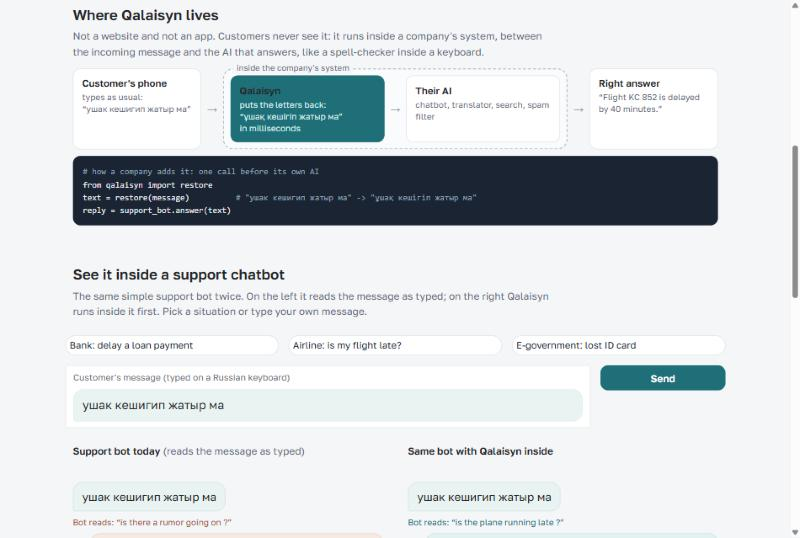

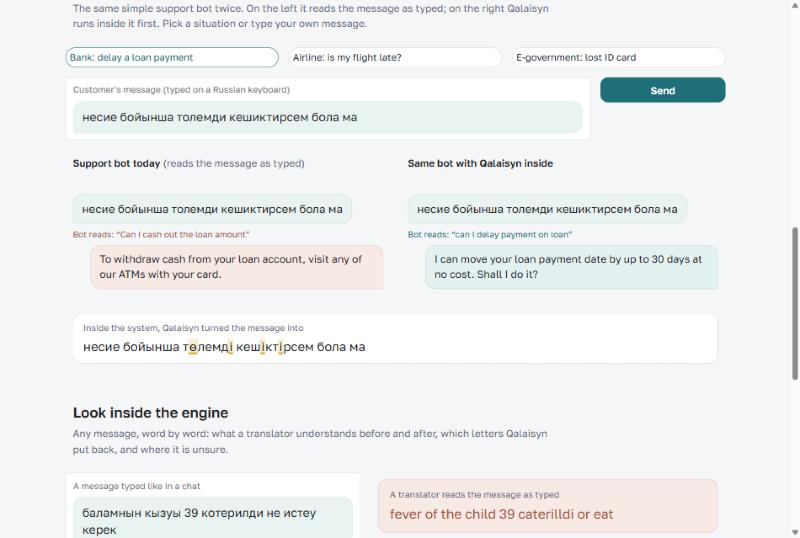

In [16]:
#@title Where Qalaisyn lives, and the same support bot with and without it (screenshots of the demo)
from IPython.display import Image, display
display(Image("figures/demo_where.jpg", width=760))
display(Image("figures/demo_chatbot.jpg", width=760))

## 1 · The problem — and who it is for

**User:** Gulnar, 62, from a village in Turkistan region. Her phone has only a Russian keyboard. One night her
grandson has a fever and she texts the clinic's chatbot:

> *баламнын кызуы 39 котерилди не истеу керек* — "my child's temperature rose to 39, what should I do"
> (standard Kazakh: *баламның қызуы 39 көтерілді не істеу керек*)

**What goes in:** a Kazakh message as people type it (Russian keyboard or Latin). **What comes out:** standard
Kazakh (Cyrillic, or the new official Latin alphabet) that any downstream AI can understand, plus suggestions for
words it is unsure about.

**Why it matters every day.** Over 13 million people speak Kazakh, and support chats, clinics and government
services are moving to AI first. A misread message means a wrong answer, a lost customer or a delayed emergency.
The same pattern exists wherever phones drop letters (Kyrgyz, Uzbek, Azerbaijani, Turkish, Vietnamese).
Live examples from our model (translator: NLLB-200; examples chosen to illustrate, overall results below):

| Service | Message as typed | AI without Qalaisyn | AI with Qalaisyn |
|---|---|---|---|
| Bank support | *несие бойынша толемди кешиктирсем бола ма* | "Can I cash out the loan amount" | "can I delay payment on loan" |
| Airline support | *ушак кешигип жатыр ма* | "is there a rumor going on?" | "is the plane running late?" |
| E-government | *жеке куалигимди жогалтып алдым не истеу керек* | "I canceled my personal credentials or need to delete them" | "I lost my ID what to do" |
| Clinic chatbot | *баламнын кызуы 39 котерилди не истеу керек* | "fever of the child 39 caterilldi or eat" | "my baby has a fever of 39 what to do" |

## 2 · Data

All data is public. Nothing from a test set is used for training.

| Purpose | Dataset | Size |
|---|---|---|
| Training text (language model + vocabulary) | Kazakh Wikipedia (Nov 2023 dump) | 1.5 M sentences |
| Training text, conversational (weighted ×20) | Tatoeba Kazakh sentences (not in test) + Kazakh film subtitles (OPUS OpenSubtitles) | ~8 k sentences |
| Russian words to leave alone | Russian word-frequency list (FrequencyWords, top 30k) | 30 k words |
| **Test 1 — everyday sentences** | Tatoeba Kazakh–English pairs | 623 sentences |
| **Test 2 — news sentences** | FLORES-200 `devtest` (Kazakh + professional English) | 1,012 sentences (300 for translation) |
| Tuning only | FLORES-200 `dev` | 997 sentences |
| Native-speaker test | messages written and corrected by our team member | see section 9 |

In [17]:
#@title Show code
# Build the corpus and test sets (downloads raw data on Colab).
RAW = ROOT / "data" / "raw"; RAW.mkdir(parents=True, exist_ok=True)
def get(url, name):
    if not (RAW / name).exists():
        subprocess.run(f'curl -sL -o "{RAW / name}" "{url}"', shell=True, check=True)
get("https://downloads.tatoeba.org/exports/per_language/kaz/kaz_sentences.tsv.bz2", "kaz_sentences.tsv.bz2")
get("https://downloads.tatoeba.org/exports/per_language/eng/eng_sentences.tsv.bz2", "eng_sentences.tsv.bz2")
get("https://downloads.tatoeba.org/exports/per_language/kaz/kaz-eng_links.tsv.bz2", "kaz-eng_links.tsv.bz2")
get("https://dl.fbaipublicfiles.com/nllb/flores200_dataset.tar.gz", "flores200.tar.gz")
get("https://huggingface.co/datasets/wikimedia/wikipedia/resolve/main/20231101.kk/train-00000-of-00001.parquet", "kkwiki.parquet")
if not (RAW / "kaz_sentences.tsv").exists():
    subprocess.run(f'cd "{RAW}" && bunzip2 -kf *.bz2 && tar -xzf flores200.tar.gz --wildcards "*kaz_Cyrl*" "*eng_Latn*" "*kir_Cyrl*"', shell=True)
P = ROOT / "data" / "processed"
if not (P / "test_tatoeba.jsonl").exists():
    import build_data; build_data.main()
for n in ["train_wiki.txt", "train_tatoeba.txt"]:
    print(n, sum(1 for _ in open(P / n, encoding="utf-8")), "sentences")
for n in ["test_tatoeba", "test_flores", "dev_flores"]:
    print(n, sum(1 for _ in open(P / f"{n}.jsonl", encoding="utf-8")), "messages (sentences x 4 writing styles)")

train_wiki.txt 1507331 sentences
train_tatoeba.txt 3950 sentences
test_tatoeba 2492 messages (sentences x 4 writing styles)
test_flores 4048 messages (sentences x 4 writing styles)
dev_flores 3988 messages (sentences x 4 writing styles)


## 3 · Simulating how people really type

We cannot use other people's private chats, so we **simulate writers**. Each simulated writer has a profile of
typing habits and keeps the same habit inside one message, like real people do.

**Cyrillic (the most common case):**
* **ru-keyboard** — a Russian keyboard: қ→к, ә→а, ө→о, ң→н, ұ/ү→у, ғ→г, һ→х, і→и (sometimes ы or Latin i)
* **partial** — has a Kazakh keyboard but types only some Kazakh letters

**Latin:**
* **careful** — close to the official Latin alphabet (q, ä, ö, ü)
* **typical** — q for қ, but drops the other special letters
* **minimal** — plain ASCII only, k for both к and қ
* **mixed** — switches habits inside a message

Real messages from a native speaker are tested separately in section 9.

In [18]:
#@title Show code
import random
from chatify import chatify, chatify_cyr, PROFILE_NAMES, CYR_PROFILES
for s in ["Баламның қызуы 39 көтерілді, не істеу керек?", "Картадан ақша кетіп қалды, мен ештеңе сатып алған жоқпын."]:
    print(s)
    for p in CYR_PROFILES:
        print(f"   {p:12s} -> {chatify_cyr(s, p, random.Random(3))}")
    for p in PROFILE_NAMES:
        print(f"   {p:12s} -> {chatify(s, p, random.Random(3))}")
if not (P / "test_tatoeba_cyr.jsonl").exists():
    import build_cyr

Баламның қызуы 39 көтерілді, не істеу керек?
   ru-keyboard  -> баламнын кызуы 39 котерилди не истеу керек
   partial      -> баламнын қызуы 39 котерілді не істеу керек
   careful      -> balamnyng qyzuy 39 köterildi ne isteu kerek
   typical      -> balamnyn qyzuy 39 koterildi ne isteu kerek
   minimal      -> balamnin kizui 39 koterildi ne isteu kerek
   mixed        -> balamnyng qızuy 39 koterildi ne isteu kerek
Картадан ақша кетіп қалды, мен ештеңе сатып алған жоқпын.
   ru-keyboard  -> картадан акша кетип калды мен ештене сатып алган жокпын
   partial      -> картадан ақша кетіп қалды мен ештене сатып алган жоқпын
   careful      -> kartadan aqsha ketip qaldy men eshtenge satyp alğan zhoqpyn
   typical      -> kartadan aqsha ketip qaldy men eshtene satyp algan zhoqpyn
   minimal      -> kartadan aksha ketip kaldy men eshtene satyp algan jokpyn
   mixed        -> kartadan aksha ketip qaldy men eshtene satıp alğan jokpyn


## 4 · Models

Restoring the letters is a guessing game that needs context: is `к`/`k` **к** or **қ**? is `а`/`a` **а** or **ә**?
is `и`/`i` **и** or **і**? is `н`/`n` **н** or **ң**? We compare five systems, from doing nothing to ours:

| Code | System | Idea |
|---|---|---|
| B0 | *raw chat* | give the chat text to the translator unchanged (size of the problem) |
| B1 | *letter rules* | every Latin letter → its most common Cyrillic letter (for Cyrillic input this changes almost nothing) |
| B2 | *dictionary* | every word → the most frequent Kazakh word that matches its letters (a strong simple baseline) |
| M1 | **Qalaisyn** | candidate words + typing-habit model + **word bigram language model** decoded with **Viterbi** over the whole sentence; unknown words are restored by a **character 5-gram model** |
| M2 | **Qalaisyn + typo search** (final) | M1, plus: real words one edit away for unknown/rare words (symmetric-delete index); Russian words inside the message are left alone; question particles typed together are split (*болама* → *бола ма*) |

All settings of M1/M2 were tuned on FLORES `dev` only. The Russian-word and particle rules were developed on a
separate set of draft chat messages, never on the test sets. To save memory, word pairs and words seen only once
are dropped: 7.1 M → 1.4 M pairs, memory 2.8 GB → 1.3 GB, with almost the same accuracy (word errors on dev
3.06% → 3.17% Latin, 2.68% → 2.63% Russian keyboard). The engine restores a message in about 7 ms on a laptop.

In [19]:
#@title Show code
import time
from eval_restore import load_lexicon, load, evaluate
from restore import RuleRestorer, DictRestorer, QalaisynRestorer
t0 = time.time()
lex = load_lexicon()           # trains on 1.5 M sentences (cached after the first run)
lex.build_fuzzy()
print(f"vocabulary {len(lex.uni):,} words · {len(lex.bi):,} word pairs · {time.time()-t0:.0f}s")
RESTORERS = [RuleRestorer(), DictRestorer(lex), QalaisynRestorer(lex),
             QalaisynRestorer(lex, fuzzy=True, name="M2 Qalaisyn+typos")]
for msg in ["баламнын кызуы 39 котерилди не истеу керек", "balamnyn qyzuy 39 koterildi ne isteu kerek"]:
    print(msg)
    for r in RESTORERS:
        print(f"   {r.name:18s} {r.restore(msg)}")

vocabulary 825,259 words · 1,398,899 word pairs · 5s
баламнын кызуы 39 котерилди не истеу керек
   B1 rules           баламнын кызуы 39 котерилди не истеу керек
   B2 dictionary      баламның қызуы 39 көтерілді не істеу керек
   M1 Qalaisyn        баламның қызуы 39 көтерілді не істеу керек
   M2 Qalaisyn+typos  баламның қызуы 39 көтерілді не істеу керек
balamnyn qyzuy 39 koterildi ne isteu kerek
   B1 rules           баламнын қызуы 39 котерілді не істеу керек
   B2 dictionary      баламның қызуы 39 көтерілді не істеу керек
   M1 Qalaisyn        баламның қызуы 39 көтерілді не істеу керек
   M2 Qalaisyn+typos  баламның қызуы 39 көтерілді не істеу керек


## 5 · Restoration results (held-out test sets)

**WER** = share of words restored wrongly, **CER** = share of letters restored wrongly (lower is better).

In [20]:
#@title Show code
import pandas as pd
tables = {}
for name in ["test_tatoeba_cyr", "test_flores_cyr", "test_tatoeba", "test_flores"]:
    tab, _ = evaluate(RESTORERS, load(name), name)
    tables[name] = tab
    df = pd.DataFrame({k: v for k, v in tab.items() if "|" not in k}).T.sort_index()
    print(f"\n{name}"); display(df.style.format("{:.1%}"))


test_tatoeba_cyr


,WER,CER
B0 raw chat,46.9%,10.8%
B1 rules,45.4%,10.1%
B2 dictionary,5.8%,1.4%
M1 Qalaisyn,2.3%,0.4%
M2 Qalaisyn+typos,3.5%,0.8%



test_flores_cyr


,WER,CER
B0 raw chat,49.8%,9.4%
B1 rules,48.2%,9.0%
B2 dictionary,3.4%,0.6%
M1 Qalaisyn,1.7%,0.2%
M2 Qalaisyn+typos,2.3%,0.4%



test_tatoeba


,WER,CER
B0 raw chat,99.9%,89.5%
B1 rules,47.6%,10.8%
B2 dictionary,6.2%,1.6%
M1 Qalaisyn,2.4%,0.4%
M2 Qalaisyn+typos,3.6%,0.8%



test_flores


,WER,CER
B0 raw chat,98.3%,89.2%
B1 rules,54.8%,10.6%
B2 dictionary,4.8%,1.0%
M1 Qalaisyn,2.3%,0.4%
M2 Qalaisyn+typos,2.9%,0.6%


In [21]:
#@title Show code
# Results broken down by writing style (the brief asks for per-group results)
rows = []
for name, tab in tables.items():
    for k, v in tab.items():
        if "|" in k:
            m, prof = k.split("|"); rows.append({"test": name, "model": m, "style": prof, "WER": v["WER"]})
display(pd.DataFrame(rows).pivot_table(index=["test", "model"], columns="style", values="WER").style.format("{:.1%}"))

## 6 · Does the meaning survive? Translation test

The real question is not letters but **meaning**. We translate every version into English with Meta's free
**NLLB-200** model (`facebook/nllb-200-distilled-600M`) and compare with the **professional English translation**
using **chrF** (higher is better). *Proper Kazakh text* is the ceiling.

`recovered = (system − raw chat) / (proper text − raw chat)`

In [22]:
#@title Show code
# Translating ~20k sentences takes a while on a laptop GPU, so the notebook loads the saved scores
# produced by `python src/eval_translate.py ...` (run it to reproduce; translations are cached).
chrf = json.loads(Path("results/translation_chrf.json").read_text())
conds = ["gold", "B0 raw chat", "B1 rules", "B2 dictionary", "M1 Qalaisyn", "M2 Qalaisyn+typos"]
out = []
for name in ["test_tatoeba_cyr", "test_flores_cyr", "test_tatoeba", "test_flores"]:
    d = chrf[name]
    row = {c: d[f"all|{c}"] for c in conds}
    row["recovered (M2)"] = (row["M2 Qalaisyn+typos"] - row["B0 raw chat"]) / (row["gold"] - row["B0 raw chat"])
    out.append(pd.Series(row, name=name))
display(pd.DataFrame(out).style.format({c: "{:.1f}" for c in conds} | {"recovered (M2)": "{:.0%}"}))

,gold,B0 raw chat,B1 rules,B2 dictionary,M1 Qalaisyn,M2 Qalaisyn+typos,recovered (M2)
test_tatoeba_cyr,60.8,45.2,45.9,59.3,60.4,59.9,94%
test_flores_cyr,52.7,42.3,42.5,52.2,52.6,52.3,95%
test_tatoeba,60.8,15.3,41.5,58.3,60.4,59.9,98%
test_flores,52.7,20.1,39.8,51.9,52.2,51.8,97%


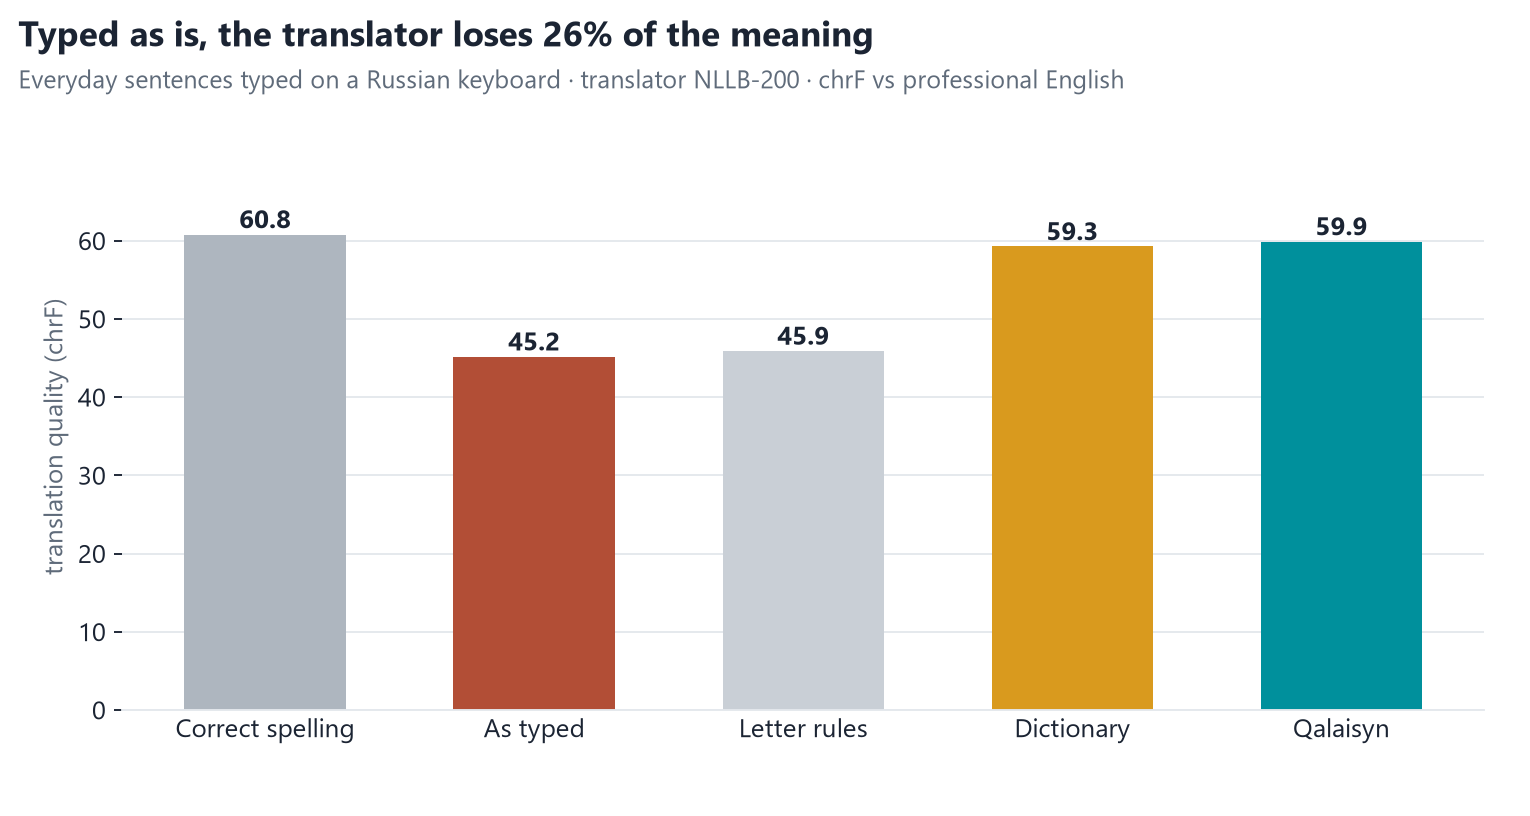

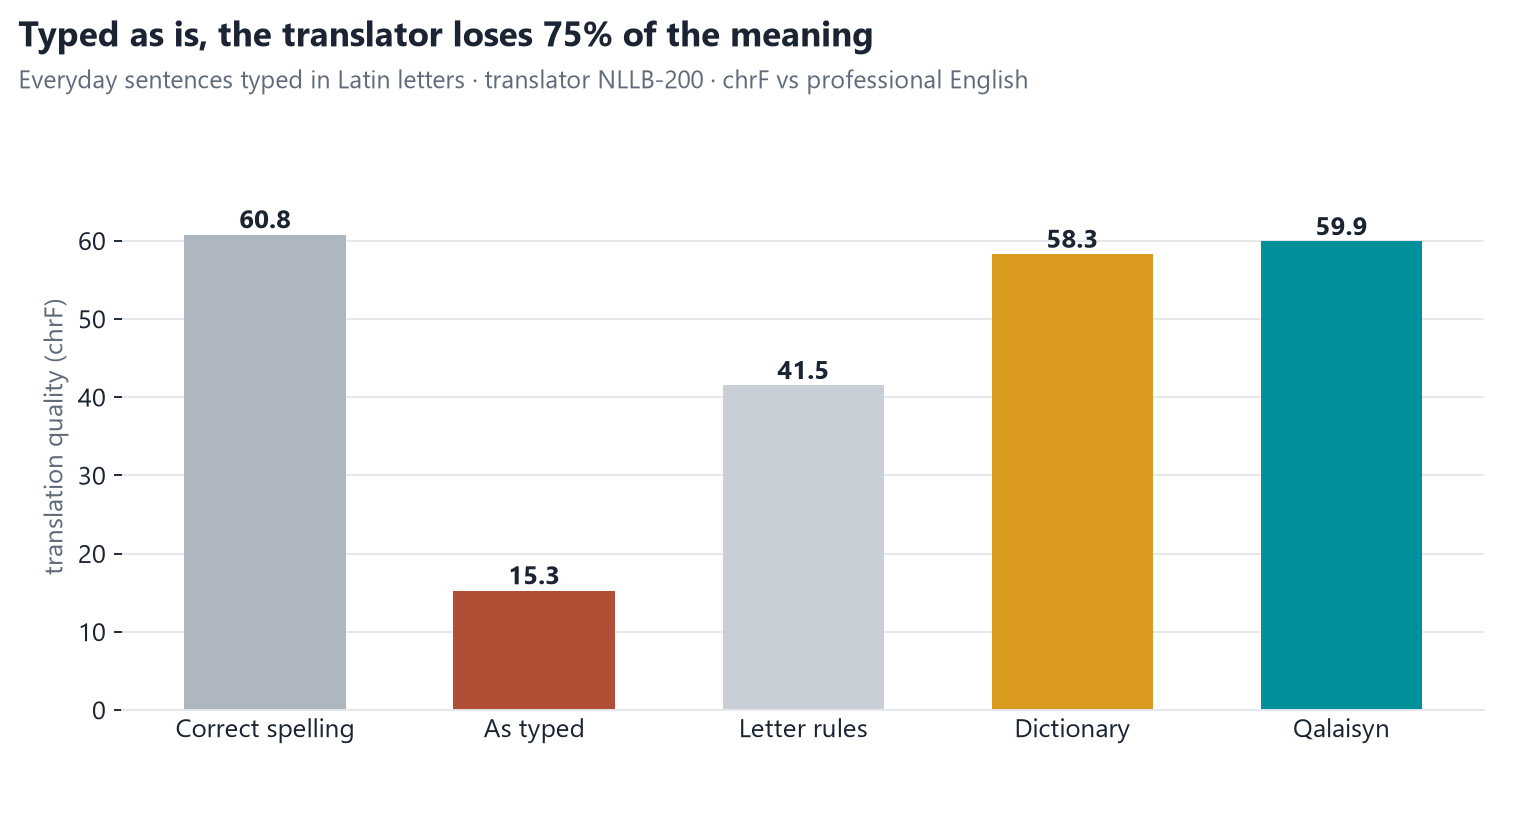

In [23]:
#@title Show code
from IPython.display import Image, display
display(Image("figures/system_test_tatoeba_cyr.png", width=760))
display(Image("figures/system_test_tatoeba.png", width=760))

In [24]:
#@title Show code
# Side by side: what the translator produced before and after Qalaisyn (Russian-keyboard messages)
tr_rows = [json.loads(l) for l in open("data/processed/translated_test_tatoeba_cyr.jsonl", encoding="utf-8")]
ex = [r for r in tr_rows if r["profile"] == "ru-keyboard" and r["chat"] != r["gold"]][5:13]
display(pd.DataFrame([{"chat message": r["chat"], "translation as typed": r["en|B0 raw chat"],
                       "translation after Qalaisyn": r["en|M2 Qalaisyn+typos"], "professional": r["eng"]} for r in ex]))

,chat message,translation as typed,translation after Qalaisyn,professional
0,жана жылынызбен,and warmth,with your new year,Happy New Year!
1,интернет пен телефонды бир жинакта сатыл ал,Sell the internet and phone in a collection,Buy the internet and phone in one set,Get both a phone and internet access in a sing...
2,сен метро да жумыс истегин келе ме,Do you have a washing machine in the metro ?,Do you want to work in the subway too ?,You want to work at METRO?!
3,кош келдиниздер,please join,you have moved,Welcome.
4,сен даретхана,you are the toilet,you are toilet,You are a toilet!
5,биздин кушимиз бирликте,our cousins in units,our strength is united,Unity is our strength!
6,жака куйылган ен бастысы,side-side width,the most important side,Freshness is our top priority.
7,еркин озинде болсын,Keep it in the free space,Make your choice,Be yourself!


## 7 · Real messages are messy — stress tests

Our clean simulation could be *too easy*, because the test messages follow the same habits the model knows. So we
asked our own question: **when does Qalaisyn break?**

* **typos-5 / typos-15:** 5% / 15% of words get a thumb typo (dropped, doubled or swapped letter);
  tested on Latin and on Russian-keyboard messages (`cyr-typos-15`)
* **unseen spellings:** a writer with habits the model was never designed for: `ae` for ә, `oe` for ө, `kh` for х, `kk` for қ

This test exposed a weakness of M1, which led to M2 (typo search). The cost: M2 is slightly worse on perfectly
clean text, but much more robust on messy text. Since real messages are messy, **M2 is our final model.**

cyr-typos-15   e.g. сен метро-да жуыс истегин келе ме  ->  сен метро-да жұмыс істегің келе ме


typos-5        e.g. sen metro-da zhumys isteging kele me  ->  сен метро-да жұмыс істегің келе ме


typos-15       e.g. sen metro-da zhumys isteging kele me  ->  сен метро-да жұмыс істегің келе ме


unseen-habits  e.g. sen metro-da jumis istegin kele me  ->  сен метро-да жұмыс істегің келе ме


condition,cyr-typos-15,typos-15,typos-5,unseen-habits
model,,,,
B0 raw chat,64.0%,100.0%,100.0%,99.7%
B1 rules,62.4%,53.6%,51.1%,63.4%
B2 dictionary,17.8%,16.4%,10.4%,38.5%
M1 Qalaisyn,14.3%,13.0%,6.6%,36.8%
M2 Qalaisyn+typos,7.9%,8.3%,5.7%,13.5%


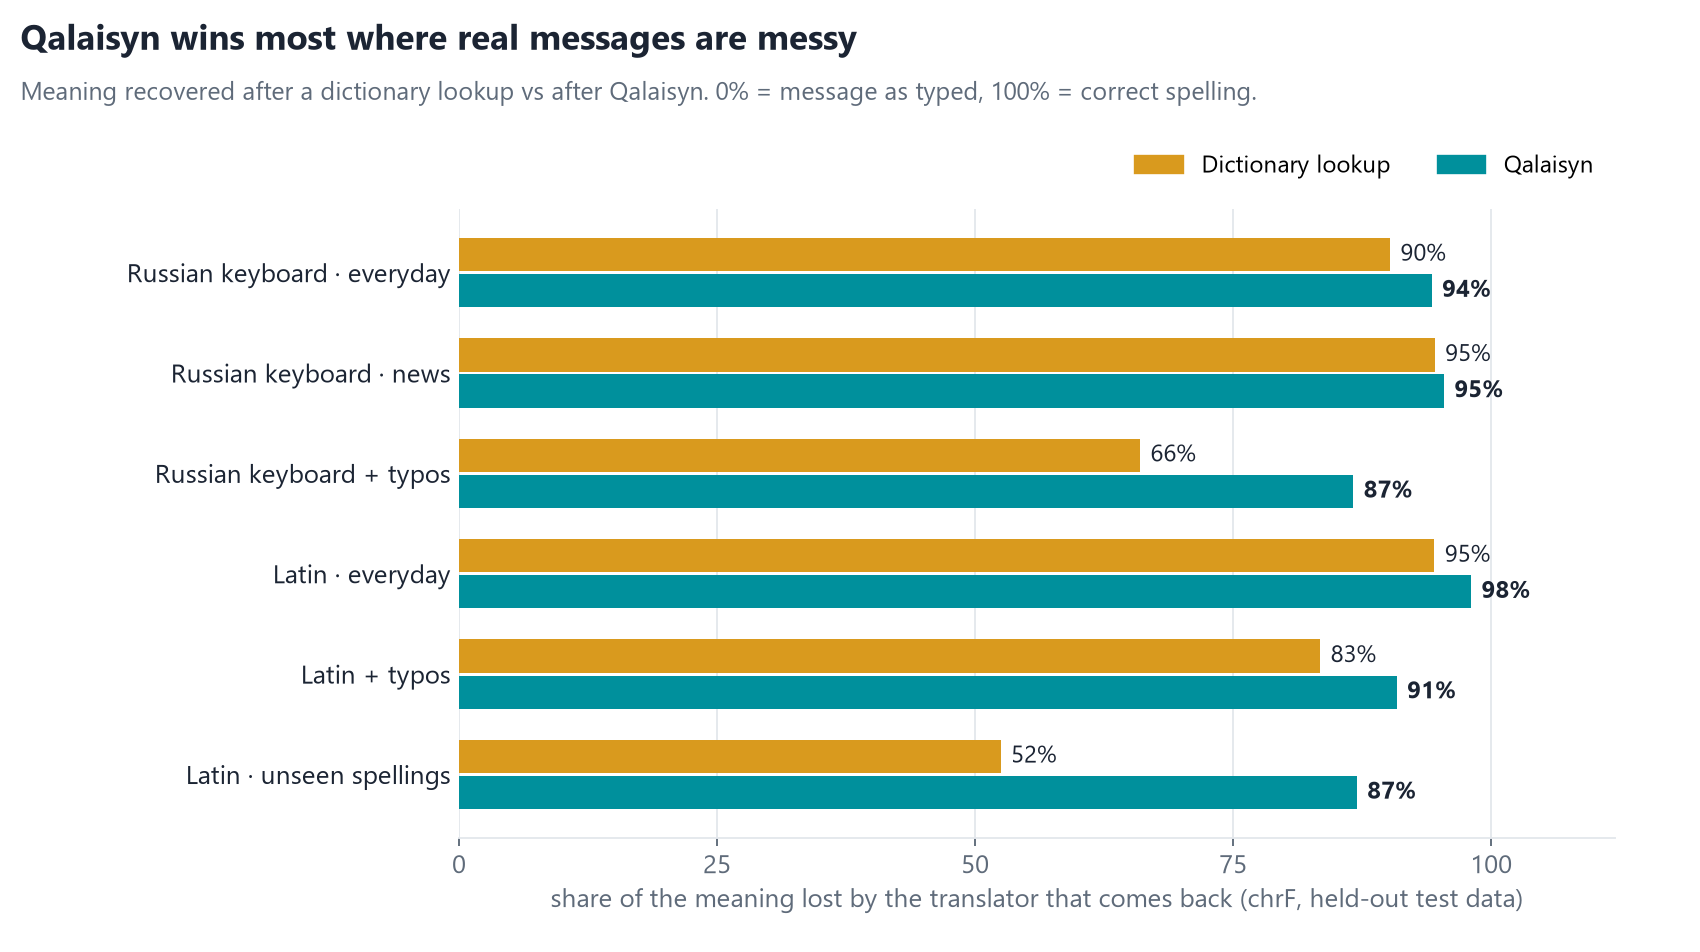

In [25]:
#@title Show code
from stress import build
stress_rows = []
for kind in ["cyr-typos-15", "typos-5", "typos-15", "unseen-habits"]:
    tab, outs = evaluate(RESTORERS, build(load("test_tatoeba"), kind), f"test_tatoeba_{kind}")
    for k, v in tab.items():
        if "|" not in k: stress_rows.append({"condition": kind, "model": k, "WER": v["WER"]})
    print(f"{kind:14s} e.g. {outs[7]['chat']}  ->  {outs[7]['M2 Qalaisyn+typos']}")
display(pd.DataFrame(stress_rows).pivot(index="model", columns="condition", values="WER").style.format("{:.1%}"))
display(Image("figures/meaning.png", width=780))

### 7b · Does it transfer to another language? Kyrgyz

Kyrgyz shares the letters ң, ө, ү with Kazakh, and Kyrgyz speakers also type on Russian keyboards or in Latin. We ran
**exactly the same code** with no changes, trained only on Kyrgyz Wikipedia, and tested on FLORES-200 Kyrgyz
(300 sentences × 3 writing styles: Russian keyboard, typical Latin, minimal Latin).

In [26]:
#@title Show code
ky = json.loads(Path("results/kyrgyz.json").read_text(encoding="utf-8"))   # produced by: python src/kyrgyz.py
print(f"Kyrgyz training sentences: {ky['train_sentences']:,}")
display(pd.DataFrame({"word error rate": ky["wer"]}).style.format("{:.1%}"))
display(pd.DataFrame(ky["chrf"]).style.format("{:.1f}"))
for st, r in ky.get("recovered_by_style", {}).items():
    print(f"Meaning recovered for Kyrgyz, {st}: {r:.0%}")
display(pd.DataFrame(ky["examples"]))

Kyrgyz training sentences: 677,030


,word error rate
B1 rules,39.9%
B2 dictionary,5.8%
M1 Qalaisyn,2.9%
M2 Qalaisyn+typos,4.1%
B0 raw chat,69.6%


,ru-keyboard,latin
gold,47.2,47.2
B0 raw chat,43.8,20.8
B2 dictionary,47.1,46.3
M2 Qalaisyn+typos,46.8,46.7


Meaning recovered for Kyrgyz, ru-keyboard: 86%
Meaning recovered for Kyrgyz, latin: 98%


,chat,ours,gold
0,ал мурун диабет оорусу менен ооруган ал эми аз...,ал мурун диабет оорусу менен ооруган ал эми аз...,ал мурун диабет оорусу менен ооруган ал эми аз...
1,al murun diabet oorusu menen oorugan al emi az...,ал мурун диабет оорусу менен ооруган ал эми аз...,ал мурун диабет оорусу менен ооруган ал эми аз...
2,al murun diabet oorusu menen oorugan al emi az...,ал мурун диабет оорусу менен ооруган ал эми аз...,ал мурун диабет оорусу менен ооруган ал эми аз...
3,канаданын диабет ассоциациясынын илимий жана к...,канаданын диабет ассоциациясынын илимий жана к...,канаданын диабет ассоциациясынын илимий жана к...
4,kanadanyn diabet assotsiatsiyasynyn ilimii jan...,канаданын диабет ассоциациясынын илимий жана к...,канаданын диабет ассоциациясынын илимий жана к...
5,kanadanyn diabet assotsiatsiyasynyn ilimii zha...,канаданын диабет ассоциациясынын илимий жана к...,канаданын диабет ассоциациясынын илимий жана к...


### 7c · Knowing when it is unsure — suggestions instead of silent mistakes

**Why.** Every model makes mistakes; the dangerous ones are *silent* mistakes. In a clinic or bank chat, a wrong
word should not be changed without anyone noticing. But asking the user about every word would be annoying.

**How.** For every word, Qalaisyn computes the probability that its choice is right, using the **forward-backward
algorithm** over the same candidate lattice and language model (it sums over *all* possible sentences, not just
the best one). If the probability is below a threshold, the word is shown as a **suggestion with 2–3 options**,
like autocorrect on a phone, instead of being changed silently. A chatbot can also skip asking and use both
options itself; asking the person makes sense only for important messages (money, health).

**Threshold.** Chosen on FLORES `dev` only: the threshold that catches the most mistakes while flagging at most
~6% of words.

**How we measure it (held-out test sets):** how many words get flagged (should be few), what share of all mistakes
fall among the flagged words (should be high), and whether the right word is among the suggestions.

threshold chosen on dev: 0.95


,words,word error rate,words shown as suggestions,mistakes among them,right word among the suggestions,error rate of the words it is sure about
test,,,,,,
"Russian keyboard, everyday",5020,3.1%,6.0%,63.0%,76.3%,1.2%
"Russian keyboard, news",13176,2.1%,5.4%,64.5%,70.2%,0.8%
"Latin chat, everyday",10030,3.3%,6.4%,64.1%,76.3%,1.3%


Is the confidence honest? (Russian keyboard, everyday)


,confidence,words,actually_correct
0,0.00-0.50,16,37.5%
1,0.50-0.70,85,56.5%
2,0.70-0.90,127,67.7%
3,0.90-0.99,362,94.8%
4,0.99-1.00,4430,98.9%


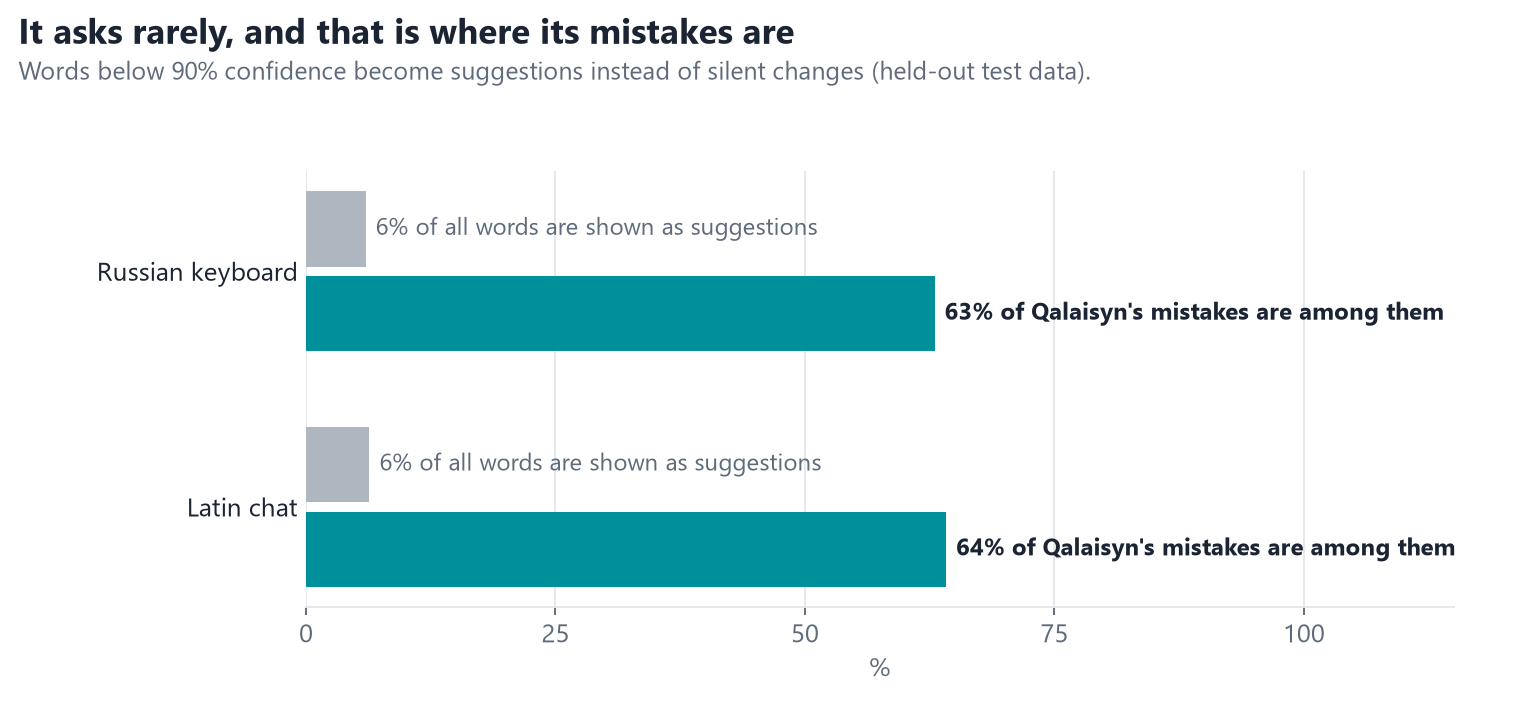

erekshe atap ot
   erekshe      -> ерекше       100%
   atap         -> атап         100%
   ot           -> от           73%  <- suggestion: от 73% / өт 27%
салем калайсын ертен мектепке барасын ба
   салем        -> сәлем        86%  <- suggestion: сәлем 86% / салем 14%
   калайсын     -> қалайсың     100%
   ертен        -> ертең        98%
   мектепке     -> мектепке     100%
   барасын      -> барасың      100%
   ба           -> ба           100%


In [27]:
#@title Show code
conf = json.loads(Path("results/confidence.json").read_text(encoding="utf-8"))   # produced by: python src/confidence.py
print("threshold chosen on dev:", conf["threshold"])
rows = []
for name, label in [("test_tatoeba_cyr", "Russian keyboard, everyday"), ("test_flores_cyr", "Russian keyboard, news"),
                    ("test_tatoeba", "Latin chat, everyday")]:
    a = conf[name]["at_threshold"]
    rows.append({"test": label, "words": a["words"], "word error rate": a["error_rate"],
                 "words shown as suggestions": a["flagged_share"], "mistakes among them": a["errors_caught"],
                 "right word among the suggestions": a["fixed_by_top3_among_flagged_errors"],
                 "error rate of the words it is sure about": a["error_rate_unflagged"]})
display(pd.DataFrame(rows).set_index("test").style.format({c: "{:.1%}" for c in rows[0] if c not in ("test", "words")}))
print("Is the confidence honest? (Russian keyboard, everyday)")
display(pd.DataFrame(conf["test_tatoeba_cyr"]["calibration"]).style.format({"actually_correct": "{:.1%}"}))
display(Image("figures/confidence.png", width=640))
q = RESTORERS[-1]
for m in ["erekshe atap ot", "салем калайсын ертен мектепке барасын ба"]:
    print(m)
    for w in q.restore_with_confidence(m):
        flag = "  <- suggestion: " + " / ".join(f"{a} {p:.0%}" for a, p in w["alternatives"] if p > 0.03) if w["confidence"] < conf["threshold"] else ""
        print(f"   {w['typed']:12s} -> {w['word']:12s} {w['confidence']:.0%}{flag}")

**Result.** On Russian-keyboard messages Qalaisyn shows only **6% of words** as suggestions,
and those words contain **63% of all its mistakes**; for
**76%** of them the right word is among the suggestions. Words it is sure
about are wrong only **1.2%** of the time. The confidence is also honest: words rated
above 99% are right about 99% of the time. Honest limit: about 4 in 10 mistakes are still made with high confidence
(mostly н/ң and і/и pairs where both words exist).

### 7d · Why a model and not just a dictionary?

A fair question: a dictionary that picks the most common spelling of each word is already good on clean text
(compare B2 and M2 in section 5). So we measured what a real system needs, with **95% bootstrap confidence
intervals** (1,000 resamples of the test messages) so that differences are not noise:

1. **Whole messages.** A chatbot needs *every* word right. We count messages restored with no mistake at all.
2. **Context.** How many of the dictionary's word mistakes Qalaisyn fixes, and how many new mistakes it makes.
3. **Messy messages.** Typos and unseen spellings, where the dictionary breaks down.
4. **Knowing when it is unsure** (section 7c): a dictionary always guesses silently.

,messages fully right: dictionary,Qalaisyn,difference (95% CI),word errors: dictionary,Qalaisyn,dictionary mistakes fixed / new mistakes,chrF difference (95% CI)
test,,,,,,,
"Russian keyboard, everyday",79.7%,88.4%,"+8.7% [+6.8%, +10.8%]",5.8%,3.5%,154 / 38,"+0.6 [+0.2, +1.1]"
"Russian keyboard, news",61.5%,71.6%,"+10.1% [+8.0%, +12.4%]",3.4%,2.3%,690 / 327,"+0.1 [-0.4, +0.6]"
"Latin chat, everyday",78.6%,87.8%,"+9.2% [+7.7%, +10.7%]",6.2%,3.6%,333 / 81,"+1.6 [+1.2, +2.0]"
Russian keyboard + 15% typos,49.0%,74.0%,"+25.0% [+21.3%, +28.4%]",17.8%,7.9%,265 / 14,"+5.1 [+3.9, +6.4]"
Latin + 15% typos,50.1%,71.6%,"+21.5% [+18.0%, +25.4%]",16.4%,8.3%,217 / 13,"+3.4 [+2.1, +4.7]"
"Latin, unseen spellings",18.6%,58.3%,"+39.6% [+35.6%, +43.5%]",38.5%,13.5%,648 / 12,"+16.1 [+14.0, +17.9]"


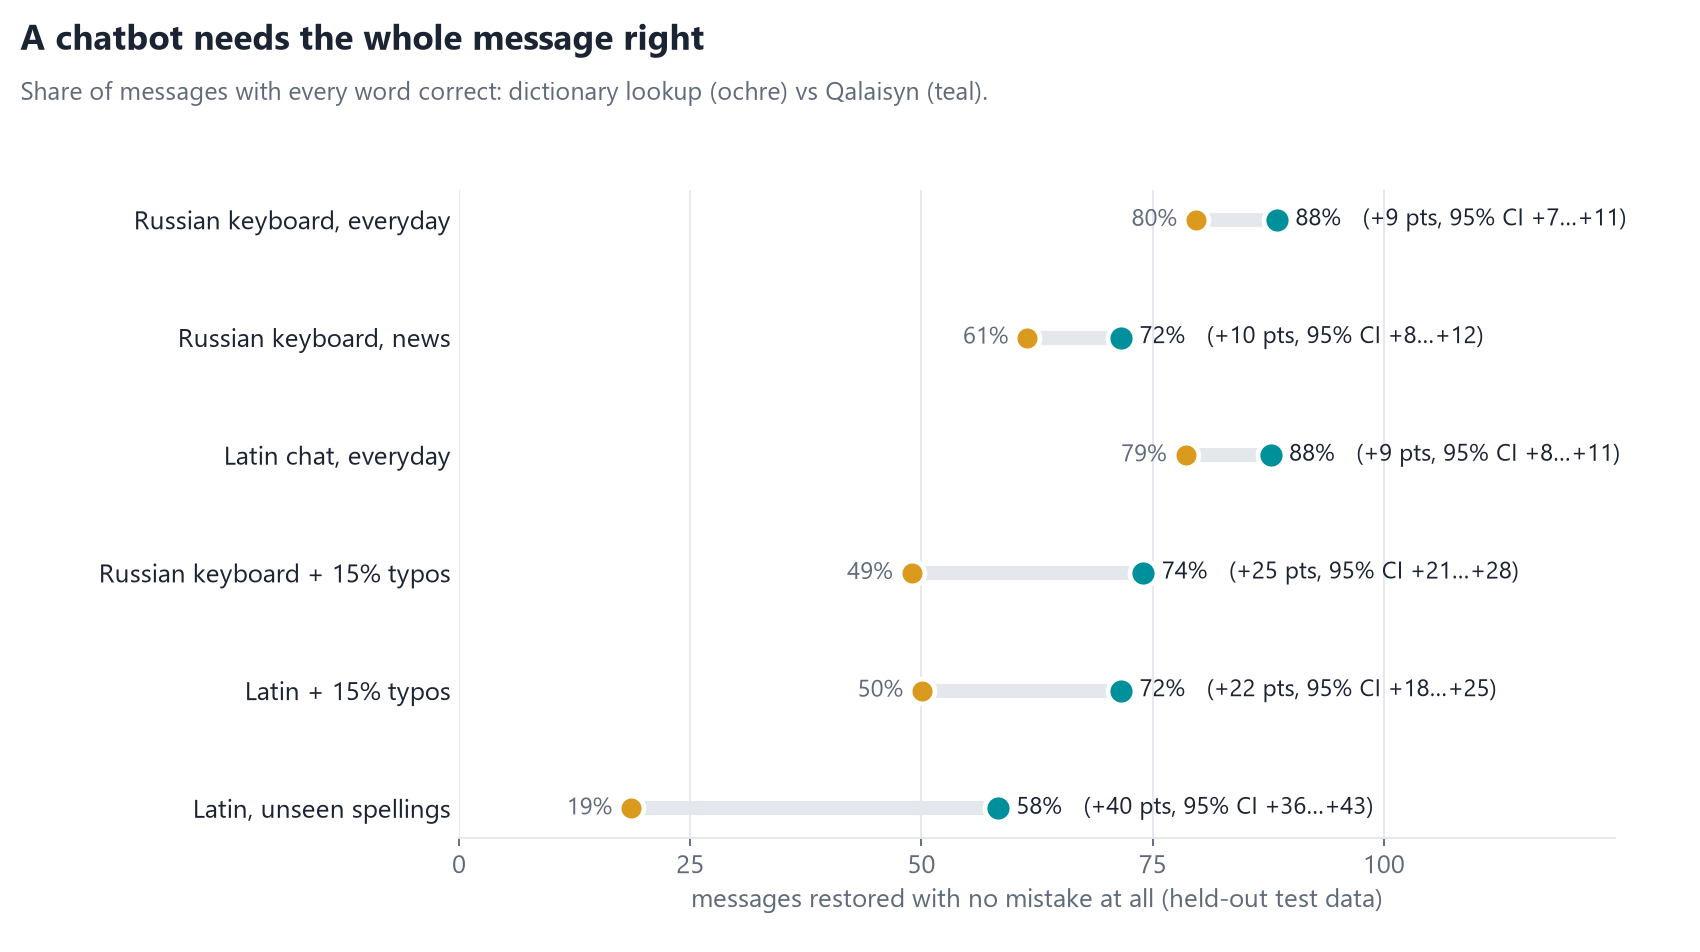

In [28]:
#@title Show code
val = json.loads(Path("results/value.json").read_text(encoding="utf-8"))   # produced by: python src/value.py
rows = []
for k, v in val.items():
    m, w = v["messages_fully_right"], v["word_error_rate"]
    row = {"test": k, "messages fully right: dictionary": m["dictionary"], "Qalaisyn": m["qalaisyn"],
           "difference (95% CI)": f"{m['qalaisyn'] - m['dictionary']:+.1%} [{m['diff_ci'][0]:+.1%}, {m['diff_ci'][1]:+.1%}]",
           "word errors: dictionary": w["dictionary"], "Qalaisyn ": w["qalaisyn"],
           "dictionary mistakes fixed / new mistakes": f"{v['dictionary_mistakes_fixed']} / {v['new_mistakes']}"}
    if "chrf" in v:
        c = v["chrf"]; row["chrF difference (95% CI)"] = f"{c['qalaisyn'] - c['dictionary']:+.1f} [{c['diff_ci'][0]:+.1f}, {c['diff_ci'][1]:+.1f}]"
    rows.append(row)
pct = {c: "{:.1%}" for c in ["messages fully right: dictionary", "Qalaisyn", "word errors: dictionary", "Qalaisyn "]}
display(pd.DataFrame(rows).set_index("test").style.format(pct))
display(Image("figures/messages.png", width=780))

**Reading the table.** On every test the confidence interval for "messages fully right" lies above zero, so the
advantage is not noise; it is largest on messy messages. On clean news text the translation scores (chrF) of the
dictionary and Qalaisyn are close, which we report honestly: the value of the model is in getting whole real
messages right, in surviving typos, and in knowing when to ask.

## 8 · Where it fails, and why

,correct letter,Qalaisyn wrote,times
0,ң,н,203
1,н,ң,168
2,і,и,145
3,ы,і,129
4,і,ы,124
5,и,і,117
6,к,қ,108
7,а,ә,87


,word error rate
1-4 words,3.5%
5-8 words,4.6%
9-15 words,4.7%
16+ words,6.0%


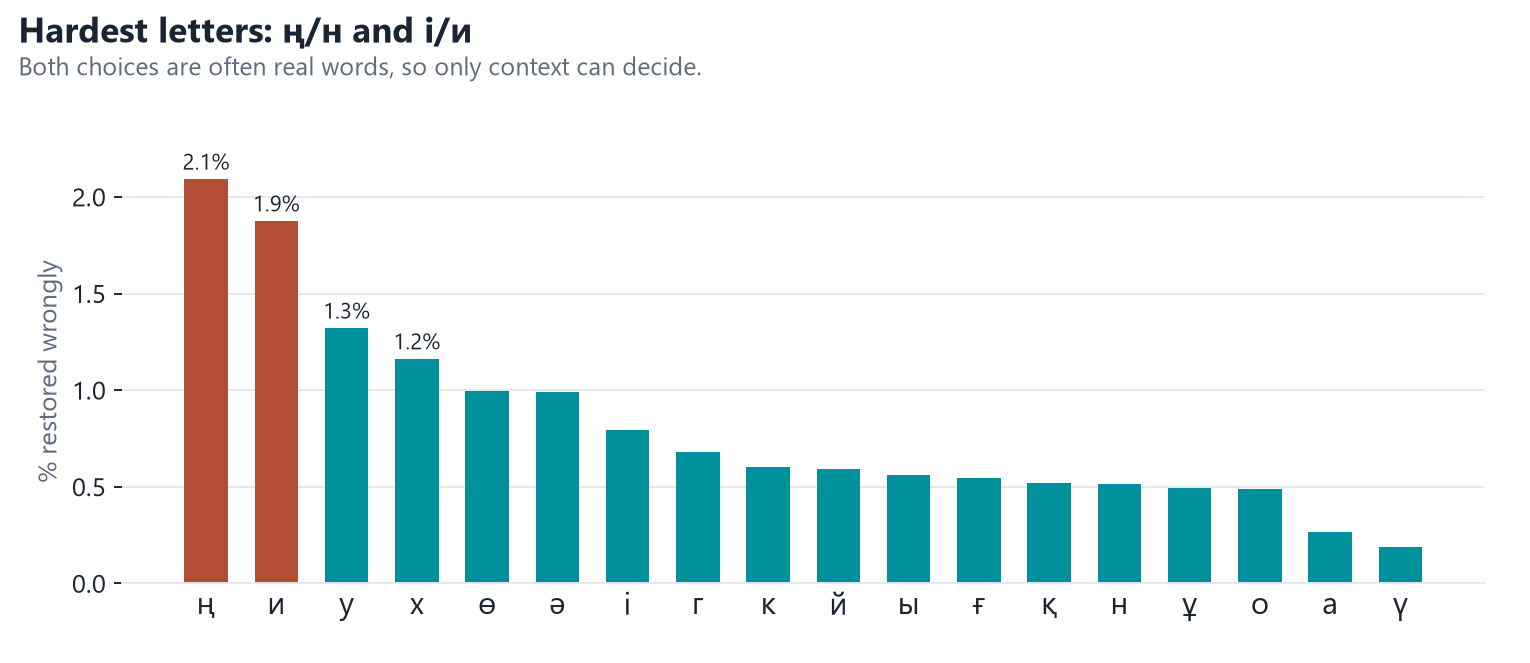

,chat,ours,reference,"wrong words (reference, ours)"
0,ерекше атап от,ерекше атап от,ерекше атап өт,"[(өт, от)]"
1,интернет пен телефонды бір жинакта сатыл ал,интернет пен телефонды бір жинақта сатып ал,интернет пен телефонды бір жинақта сатыл ал,"[(сатыл, сатып)]"
2,барлык адамдар тумысынан азат жане кадыр-касие...,барлық адамдар тумысынан азат және қадір-қасие...,барлық адамдар тумысынан азат және қадір-қасие...,"[(кұқықтары, құқықтары)]"
3,айда ауа жок,аида ауа жоқ,айда ауа жоқ,"[(айда, аида)]"
4,сен кайда барасын,сэн қайда барасың,сен қайда барасың,"[(сен, сэн)]"
5,рине коп кателер болатын шыгар,әрине көп қателер болатын шығар,рине көп қателер болатын шығар,"[(рине, әрине)]"
6,мать тереза жаксы йел болды ма,мать тереза жақсы йель болды ма,мать тереза жақсы йел болды ма,"[(йел, йель)]"
7,сосын пайгамдар кайтыс болганнан кейин биз таг...,сосын пайғамбар қайтыс болғаннан кейін біз тағ...,сосын пайғамдар қайтыс болғаннан кейін біз тағ...,"[(пайғамдар, пайғамбар), (жалғызбыз, жалғызбын)]"
8,биз осылай отирек айтканда биз озимиз туралы х...,біз осылай тірек айтқанда біз өзіміз туралы ха...,біз осылай өтірек айтқанда біз өзіміз туралы х...,"[(өтірек, тірек)]"
9,кайда жумыс истейсин,қайда жұмыс істейсің,қайда жұмыс істейсін,"[(істейсін, істейсің)]"


In [29]:
#@title Show code
import analysis
data = sum((analysis.rows(n) for n in ["test_tatoeba", "test_flores", "test_tatoeba_cyr", "test_flores_cyr"]), [])
rates, conf = analysis.letter_errors(data)
display(pd.DataFrame([{"correct letter": a, "Qalaisyn wrote": b, "times": n} for (a, b), n in conf.most_common(8)]))
order = ["1-4 words", "5-8 words", "9-15 words", "16+ words"]
bl = analysis.by_length(data)
display(pd.DataFrame({"word error rate": {k: bl[k] for k in order}}).style.format("{:.1%}"))
display(Image("figures/letters.png", width=640))
fails = analysis.failures(analysis.rows("test_tatoeba_cyr"), n=40)
display(pd.DataFrame([{"chat": x["chat"], "ours": x["ours"], "reference": x["gold"],
                       "wrong words (reference, ours)": x["wrong"]} for x in fails[::4]]))

**What we learned from the failures**

1. **н vs ң and і vs ы vs и** are the hardest letters: these pairs often produce two real words (e.g. *-ның* vs
   *-нің* endings after an ambiguous vowel), so only context can decide, and our bigram context is short.
2. **True ambiguity:** *ot* can be **от** (fire) or **өт** (pass/go) — "Erekshe atap ot!" is a one-word-context case.
3. **Some "errors" are mistakes in the reference.** Tatoeba writes *қагаз* and *сатыл ал*; the correct spellings are
   **қағаз** (paper) and **сатып ал** (buy) — exactly what Qalaisyn produced. Our scores are therefore slightly
   pessimistic.
4. **Unseen spellings** (`kk`, `ae`) are still the weakest condition (≈13–15% word errors), see section 7.

## 9 · Native-speaker check: real messages

Simulated messages follow rules we wrote, so the real test is messages written by a person. A native Kazakh speaker
(a friend of the team, with permission) went through everyday situations and, for each one, typed the message
exactly as they would in a chat, then wrote its correct spelling (`data/real/ДЛЯ_ДРУГА.csv`). These messages were
never used for development or tuning. No English references exist for them, so meaning is measured against the
translation of the *correct* spelling.

In [30]:
#@title Show code
import real_eval
real_rows = real_eval.load_rows()
if real_rows:
    tab, outs = evaluate(RESTORERS, real_rows, "real")
    print(f"{len(real_rows)} native-speaker messages")
    display(pd.DataFrame({k: v for k, v in tab.items() if "|" not in k}).T.style.format("{:.1%}"))
    rows = []
    for k, v in tab.items():
        if "|" in k:
            m, s = k.split("|"); rows.append({"model": m, "style": s, "WER": v["WER"]})
    display(pd.DataFrame(rows).pivot(index="model", columns="style", values="WER").style.format("{:.1%}"))
    display(pd.DataFrame([{"as typed": o["chat"], "Qalaisyn": o["M2 Qalaisyn+typos"], "correct": o["gold"],
                           "right?": "yes" if o["M2 Qalaisyn+typos"] == o["gold"] else "no"} for o in outs]))
else:
    print("Native-speaker messages are being collected (data/real/ДЛЯ_ДРУГА.csv).")

Native-speaker messages are being collected (data/real/ДЛЯ_ДРУГА.csv).


## 10 · Try it yourself

Qalaisyn is not a website or an app: it is an engine that runs **inside** other systems, between an incoming
message and the AI that answers it. The demo page is only a window into it:

1. *Why one missing letter matters* — explained for people who do not speak Kazakh;
2. *Where Qalaisyn lives* — the customer's phone → **Qalaisyn inside the company's system** → their AI → the answer;
3. *See it inside a support chatbot* — the same simple support bot twice: reading the message as typed, and with
   Qalaisyn inside. Without it the bot answers the wrong question (e.g. "how to withdraw cash" instead of
   "delay a loan payment"); with it, the bot answers correctly. (The bot is a simple keyword bot for demonstration;
   the replies come from the live model's translation.)
4. *Look inside the engine* — any message, word by word, with suggestions for unsure words.

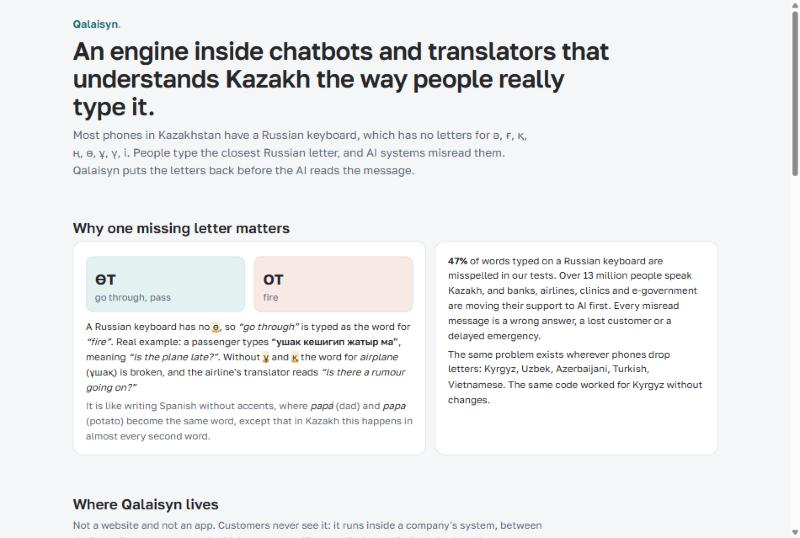

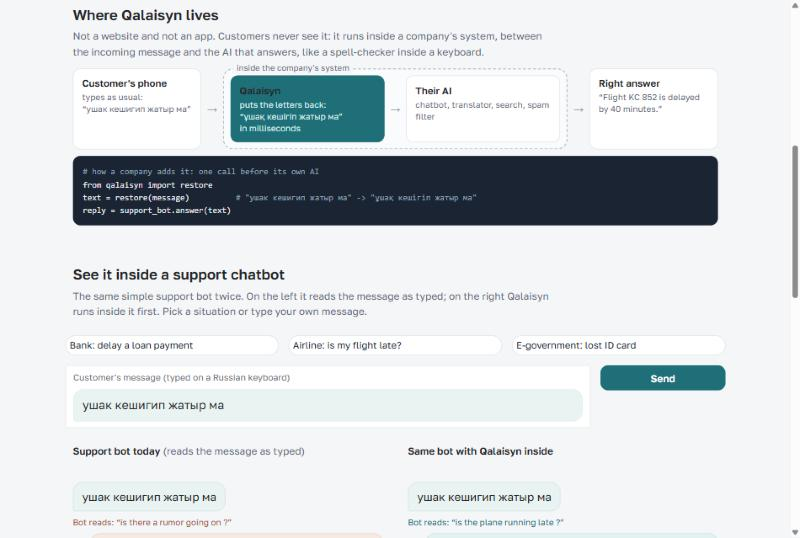

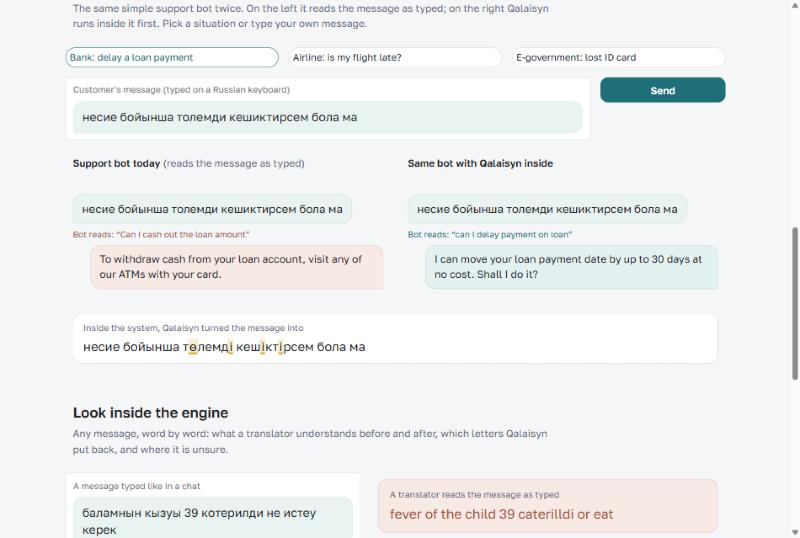

In [31]:
#@title Show code
from IPython.display import Image, display
display(Image("figures/demo.jpg", width=760))
display(Image("figures/demo_where.jpg", width=760))
display(Image("figures/demo_chatbot.jpg", width=760))

**Run the demo yourself (Google Colab):** run all cells above (≈10 min the first time: it downloads the data and
the translation model), then run the next cell. It prints a public link to the demo page, valid for 72 hours.

In [32]:
#@title Show code
if IN_COLAB:
    subprocess.run("pip -q install gradio==5.9.1", shell=True)
    import app
    app.demo.launch(share=True, debug=False)
else:
    print("On a local machine run:  python src/app.py   (then open http://localhost:7860)")

On a local machine run:  python src/app.py   (then open http://localhost:7860)


In [33]:
#@title Show code
import warnings; warnings.filterwarnings("ignore")
from eval_translate import Translator
TR = Translator()
qal = RESTORERS[-1]
for m in ["баламнын кызуы 39 котерилди не истеу керек",
          "ажеме жедел жардем керек уйге келиниз",
          "kartadan aqsha ketip qaldy men eshtene satyp algan joqpyn"]:
    fixed = qal.restore(m)
    before, after = TR.translate([m, fixed])
    print(f"chat:   {m}\n  AI as typed:  {before}\n  Qalaisyn:     {fixed}\n  AI after:     {after}\n")

chat:   баламнын кызуы 39 котерилди не истеу керек
  AI as typed:  fever of the child 39 caterilldi or eat
  Qalaisyn:     баламның қызуы 39 көтерілді не істеу керек
  AI after:     my baby has a fever of 39 what to do

chat:   ажеме жедел жардем керек уйге келиниз
  AI as typed:  need urgent assistance to my grandmother
  Qalaisyn:     әжеме жедел жәрдем керек үйге келіңіз
  AI after:     please come to the house where grandmother needs emergency care

chat:   kartadan aqsha ketip qaldy men eshtene satyp algan joqpyn
  AI as typed:  from the card aqsha ketip qaldy men eshtene satyp algan joqpyn
  Qalaisyn:     картадан ақша кетіп қалды мен ештеңе сатып алған жоқпын
  AI after:     I didn 't buy anything .



*Note on the last example:* Qalaisyn restored every word correctly, but the translator dropped the first half of the sentence
("money disappeared from my card"). That is a limit of the translation model, not of the restoration — and a reminder
that chrF also measures the translator's own mistakes, which are the same for every system we compare.

## 11 · Limitations, next steps and sources

**Limitations**
* Most test messages are simulated from typing-habit profiles; the native-speaker set is small.
* The language model is trained mostly on Wikipedia (plus Tatoeba and film subtitles), which is more formal than
  chats. Merged question particles (*болама* → *бола ма*) and common Russian words (*доставка*, *короче*, *щас*) are
  now handled, but rarer colloquial forms and slang can still be "corrected" into the wrong Kazakh word.
* Rare word forms (seen fewer than twice in training) were dropped to save memory; typo search can then replace a
  rare but correct form with a more common neighbour (*телефоным* → *телефоны*).
* Translation quality is measured automatically with chrF.

**Next steps**
1. A longer context model (word trigrams or a small neural model) for the н/ң and і/ы/и cases.
2. More languages (Kyrgyz already works with zero code changes, section 7b; Uzbek, Azerbaijani next) and a plug-in
   for chatbots of public services.

**Sources and tools**
* Data: [Tatoeba](https://tatoeba.org) (CC BY 2.0 FR) · [FLORES-200](https://github.com/facebookresearch/flores) (CC BY-SA 4.0) ·
  [Kazakh Wikipedia via Hugging Face `wikimedia/wikipedia`](https://huggingface.co/datasets/wikimedia/wikipedia) (CC BY-SA)
* Model: [NLLB-200 distilled 600M](https://huggingface.co/facebook/nllb-200-distilled-600M) (Meta, CC BY-NC 4.0) — used only for evaluation
* Libraries: PyTorch, Hugging Face Transformers, sacrebleu (chrF), pandas, matplotlib, Gradio
* AI tools: Claude (Anthropic) helped write code and text; every part was reviewed and explained to the team.

*This project is a prototype and is not medical or financial advice.*